In [18]:
import sys
from pathlib import Path
# dont need this if using pip install -e .
project_root = Path.cwd().resolve().parent
sys.path.insert(0, str(project_root))
print("Using project root:", project_root)

Using project root: /home/mbz/Documents/PhD


In [19]:
from src.config import PipelineConfig
from src.pipeline import SensorPipeline
from src.logging_utils import setup_logging
config = PipelineConfig.from_yaml(Path("config/sensors.yaml"))
print(f"Loaded {len(config.sensors)} sensors:")
for s in config.sensors:
    print(f"  - {s.name} ({s.sensor_type}, altitude: {s.altitude_m}m)")
setup_logging(config.log_dir, log_name="notebook_run")

pipeline = SensorPipeline(config, force=False)

2026-01-19 15:24:37,968 - root - INFO - Logging initialized. Log file: /home/mbz/Documents/PhD/SCD41_DATA/output/logs/notebook_run_20260119_152437.log


Loaded 5 sensors:
  - CO2_SCT1_2M (scd41, altitude: 2m)
  - CO2_30M_A (scd41, altitude: 30m)
  - CO2_30M_B (scd41, altitude: 30m)
  - CO2_30M_C (scd41, altitude: 30m)
  - LGR_30M (lgr_csv, altitude: 30m)


In [20]:
pipeline.run_all(year=2024, month=9)

2026-01-19 15:24:51,313 - src.pipeline - INFO - Starting pipeline for all sensors
2026-01-19 15:24:51,314 - src.pipeline - INFO - ============================================================
2026-01-19 15:24:51,314 - src.pipeline - INFO - Processing sensor: CO2_SCT1_2M
2026-01-19 15:24:51,314 - src.pipeline - INFO - ============================================================
2026-01-19 15:24:51,432 - src.pipeline - INFO - Found 19 days ((2024, 9, 12) to (2024, 9, 30))
2026-01-19 15:24:51,435 - src.processor - INFO - Processing 2024-09-12 (13 files)
2026-01-19 15:24:53,958 - src.processor - INFO - Removed 31389 duplicate timestamps
2026-01-19 15:24:53,960 - src.uptime - WARNING - Unexpected sample interval: 2.0s (expected ~60s)
2026-01-19 15:24:53,981 - src.processor - INFO - ✓ 2024-09-12: 16068 raw → 67 10-min samples (uptime: 100.0%)
2026-01-19 15:24:53,984 - src.processor - INFO - Processing 2024-09-13 (24 files)
2026-01-19 15:24:59,273 - src.processor - INFO - Removed 68209 duplica

In [21]:
pipeline.run_all(year=2024, month=10)

2026-01-19 15:27:09,779 - src.pipeline - INFO - Starting pipeline for all sensors
2026-01-19 15:27:09,780 - src.pipeline - INFO - ============================================================
2026-01-19 15:27:09,780 - src.pipeline - INFO - Processing sensor: CO2_SCT1_2M
2026-01-19 15:27:09,780 - src.pipeline - INFO - ============================================================
2026-01-19 15:27:09,857 - src.pipeline - INFO - Found 31 days ((2024, 10, 1) to (2024, 10, 31))
2026-01-19 15:27:09,859 - src.processor - INFO - Processing 2024-10-01 (24 files)
2026-01-19 15:27:15,578 - src.processor - INFO - Removed 71891 duplicate timestamps
2026-01-19 15:27:15,582 - src.uptime - WARNING - Unexpected sample interval: 4.0s (expected ~60s)
2026-01-19 15:27:15,625 - src.processor - INFO - ✓ 2024-10-01: 31512 raw → 144 10-min samples (uptime: 100.0%)
2026-01-19 15:27:15,629 - src.processor - INFO - Processing 2024-10-02 (24 files)
2026-01-19 15:27:21,521 - src.processor - INFO - Removed 75893 dupli

In [22]:
pipeline.run_all(year=2024, month=11)

2026-01-19 15:39:40,248 - src.pipeline - INFO - Starting pipeline for all sensors
2026-01-19 15:39:40,248 - src.pipeline - INFO - ============================================================
2026-01-19 15:39:40,249 - src.pipeline - INFO - Processing sensor: CO2_SCT1_2M
2026-01-19 15:39:40,249 - src.pipeline - INFO - ============================================================
2026-01-19 15:39:40,339 - src.pipeline - INFO - Found 30 days ((2024, 11, 1) to (2024, 11, 30))
2026-01-19 15:39:40,342 - src.processor - INFO - Processing 2024-11-01 (24 files)
2026-01-19 15:39:46,259 - src.processor - INFO - Removed 68470 duplicate timestamps
2026-01-19 15:39:46,262 - src.uptime - WARNING - Unexpected sample interval: 2.0s (expected ~60s)
2026-01-19 15:39:46,301 - src.processor - INFO - ✓ 2024-11-01: 33595 raw → 140 10-min samples (uptime: 100.0%)
2026-01-19 15:39:46,307 - src.processor - INFO - Processing 2024-11-02 (24 files)
2026-01-19 15:39:52,198 - src.processor - INFO - Removed 68459 dupli

In [23]:
# After regenerating September with fixed code:
import pandas as pd
# 1. Check for duplicates in individual CSVs
for sensor in ['CO2_SCT1_2M', 'CO2_30M_A', 'CO2_30M_B']:
    df = pd.read_csv(f'output/individual/{sensor}_10min.csv', parse_dates=['timestamp'])
    dups = df['timestamp'].duplicated().sum()
    print(f"{sensor}: {dups} duplicates")

CO2_SCT1_2M: 0 duplicates
CO2_30M_A: 0 duplicates
CO2_30M_B: 0 duplicates


# todo:
 - add more plot types
 - automate plot generation for all months
 - fix taylor plot
 - add options for different time resolutions (hourly, daily)
 - add options for different date ranges
 - improve plot aesthetics

# Validation Checklist 😅

In [24]:
from pathlib import Path
import pandas as pd

output_dir = Path("output/individual")
parquet_dir = Path("output/parquet")

print("=" * 60)
print("POST-PROCESSING VALIDATION")
print("=" * 60)

# 1. Check column names are clean (no <lambda>)
print("\n1. COLUMN NAME CHECK")
for csv_file in sorted(output_dir.glob("*_10min.csv")):
    df = pd.read_csv(csv_file, nrows=1)
    bad_cols = [c for c in df.columns if '<lambda>' in c]
    status = "❌ " + str(bad_cols) if bad_cols else "✓"
    print(f"   {csv_file.name}: {status}")

# 2. Check monthly CSV files exist (NEW)
print("\n2. MONTHLY CSV FILES")
for sensor in ["CO2_SCT1_2M", "CO2_30M_A", "CO2_30M_B", "CO2_30M_C", "LGR_30M"]:
    monthly_csvs = list(output_dir.glob(f"{sensor}_2024_*.csv"))
    print(f"   {sensor}: {len(monthly_csvs)} monthly files")

# 3. Check parquet files exist
print("\n3. MONTHLY PARQUET FILES")
for sensor in ["CO2_SCT1_2M", "CO2_30M_A", "CO2_30M_B", "CO2_30M_C", "LGR_30M"]:
    monthly_pqs = list(parquet_dir.glob(f"{sensor}_2024_*.parquet"))
    print(f"   {sensor}: {len(monthly_pqs)} parquet files")

# 4. CSV vs Parquet row count consistency
print("\n4. CSV/PARQUET CONSISTENCY (November sample)")
for sensor in ["CO2_SCT1_2M", "LGR_30M"]:
    csv_path = output_dir / f"{sensor}_2024_11.csv"
    pq_path = parquet_dir / f"{sensor}_2024_11.parquet"
    if csv_path.exists() and pq_path.exists():
        csv_rows = len(pd.read_csv(csv_path))
        pq_rows = len(pd.read_parquet(pq_path))
        match = "✓" if csv_rows == pq_rows else f"❌ ({csv_rows} vs {pq_rows})"
        print(f"   {sensor}: {match}")

# 5. Data sanity check
print("\n5. DATA SANITY (LGR November)")
lgr_csv = output_dir / "LGR_30M_2024_11.csv"
if lgr_csv.exists():
    df = pd.read_csv(lgr_csv, parse_dates=['timestamp'])
    print(f"   Rows: {len(df)}")
    print(f"   Date range: {df['timestamp'].min()} to {df['timestamp'].max()}")
    print(f"   CO2_dry_mean range: {df['CO2_dry_mean'].min():.1f} - {df['CO2_dry_mean'].max():.1f} ppm")
    
    # Check for time gaps
    time_diffs = df['timestamp'].diff()
    gaps = time_diffs[time_diffs > pd.Timedelta(minutes=10)]
    print(f"   Time gaps >10min: {len(gaps)}")

print("\n" + "=" * 60)

POST-PROCESSING VALIDATION

1. COLUMN NAME CHECK
   CO2_30M_A_10min.csv: ✓
   CO2_30M_B_10min.csv: ✓
   CO2_30M_C_10min.csv: ✓
   CO2_SCT1_2M_10min.csv: ✓
   LGR_30M_10min.csv: ✓

2. MONTHLY CSV FILES
   CO2_SCT1_2M: 3 monthly files
   CO2_30M_A: 3 monthly files
   CO2_30M_B: 0 monthly files
   CO2_30M_C: 2 monthly files
   LGR_30M: 3 monthly files

3. MONTHLY PARQUET FILES
   CO2_SCT1_2M: 3 parquet files
   CO2_30M_A: 3 parquet files
   CO2_30M_B: 0 parquet files
   CO2_30M_C: 2 parquet files
   LGR_30M: 3 parquet files

4. CSV/PARQUET CONSISTENCY (November sample)
   CO2_SCT1_2M: ✓
   LGR_30M: ✓

5. DATA SANITY (LGR November)
   Rows: 4320
   Date range: 2024-11-01 00:00:00 to 2024-11-30 23:50:00
   CO2_dry_mean range: 402.5 - 426.3 ppm
   Time gaps >10min: 0



# merging sensor data 🚀

In [25]:
# Reload the module to get the updated merger
import importlib
import src.merger
importlib.reload(src.merger)

from src.merger import merge_all_sensors


# # Option 1: Use default paths (recommended)
# merged = merge_all_sensors(
#     individual_dir=config.output_dir,
#     sensor_names=[s.name for s in config.sensors],
#     start_date='2024-09-01',
#     end_date='2024-09-30'
# )
# Creates: output/merged/SMEAR_EE_CO2_merged.csv
#          output/merged/parquet/SMEAR_EE_CO2_2024_09_merged.parquet

# # Option 2: Custom paths
# merged = merge_all_sensors(
#     individual_dir=config.output_dir,
#     sensor_names=[s.name for s in config.sensors],
#     output_dir=Path("/home/mbz/Documents/PhD/SCD41_DATA/output/merged"),
#     parquet_dir=Path("/home/mbz/Documents/PhD/SCD41_DATA/output/parquet_merged")
# )



from src.merger import merge_all_sensors

merged = merge_all_sensors(
    individual_dir=config.output_dir,
    sensor_names=[s.name for s in config.sensors],
    output_dir=Path("output/merged")
)

print(f"Merged dataset shape: {merged.shape}")
print(f"Date range: {merged.index.min()} to {merged.index.max()}")
print(f"\nColumns: {list(merged.columns)}")

# check for any remaining '<lambda>' in column names...
print(f"Columns with '<lambda>': {[c for c in merged.columns if '<lambda>' in c]}")

2026-01-19 15:55:08,715 - src.merger - INFO - Merging 5 sensors...
2026-01-19 15:55:08,716 - src.merger - INFO -   Loading CO2_SCT1_2M...
2026-01-19 15:55:08,732 - src.merger - INFO -     10942 rows (2024-09-12 12:20:00 to 2024-11-30 23:10:00)
2026-01-19 15:55:08,733 - src.merger - INFO -   Loading CO2_30M_A...
2026-01-19 15:55:08,741 - src.merger - INFO -     5039 rows (2024-09-19 11:10:00 to 2024-11-29 23:50:00)
2026-01-19 15:55:08,742 - src.merger - INFO -   Loading CO2_30M_B...
2026-01-19 15:55:08,751 - src.merger - INFO -     4386 rows (2024-09-19 11:10:00 to 2024-11-30 23:40:00)
2026-01-19 15:55:08,751 - src.merger - INFO -   Loading CO2_30M_C...
2026-01-19 15:55:08,762 - src.merger - INFO -     8483 rows (2024-10-02 09:30:00 to 2024-11-30 23:40:00)
2026-01-19 15:55:08,763 - src.merger - INFO -   Loading LGR_30M...
2026-01-19 15:55:08,814 - src.merger - INFO -     13104 rows (2024-09-01 00:00:00 to 2024-11-30 23:50:00)
2026-01-19 15:55:08,814 - src.merger - INFO -   Merging on ti

Merged dataset shape: (13104, 101)
Date range: 2024-09-01 00:00:00 to 2024-11-30 23:50:00

Columns: ['co2_sct1_2m_co2_mean', 'co2_sct1_2m_co2_std', 'co2_sct1_2m_co2_count', 'co2_sct1_2m_temp_mean', 'co2_sct1_2m_temp_std', 'co2_sct1_2m_temp_count', 'co2_sct1_2m_humidity_mean', 'co2_sct1_2m_humidity_std', 'co2_sct1_2m_humidity_count', 'co2_sct1_2m_co2_qc', 'co2_sct1_2m_temp_qc', 'co2_sct1_2m_humidity_qc', 'co2_30m_a_co2_mean', 'co2_30m_a_co2_std', 'co2_30m_a_co2_count', 'co2_30m_a_temp_mean', 'co2_30m_a_temp_std', 'co2_30m_a_temp_count', 'co2_30m_a_humidity_mean', 'co2_30m_a_humidity_std', 'co2_30m_a_humidity_count', 'co2_30m_a_co2_qc', 'co2_30m_a_temp_qc', 'co2_30m_a_humidity_qc', 'co2_30m_b_co2_mean', 'co2_30m_b_co2_std', 'co2_30m_b_co2_count', 'co2_30m_b_temp_mean', 'co2_30m_b_temp_std', 'co2_30m_b_temp_count', 'co2_30m_b_humidity_mean', 'co2_30m_b_humidity_std', 'co2_30m_b_humidity_count', 'co2_30m_b_co2_qc', 'co2_30m_b_temp_qc', 'co2_30m_b_humidity_qc', 'co2_30m_c_co2_mean', 'co2_30

# Plots! 📈

Generating plots...
  - CO2_SCT1_2M: Uptime timeseries


2026-01-19 16:05:33,197 - UptimePlots - INFO - Saved: CO2_SCT1_2M_uptime_timeseries.png


  - CO2_SCT1_2M: Uptime heatmap


2026-01-19 16:05:33,580 - UptimePlots - INFO - Saved: CO2_SCT1_2M_uptime_heatmap.png


  - CO2_SCT1_2M: QC summary


2026-01-19 16:05:33,987 - QualityControlPlots - INFO - Saved: CO2_SCT1_2M_qc_summary.png


... (24 outputs left out)

  - Multi-sensor uptime summary


2026-01-19 16:05:38,345 - UptimePlots - INFO - Saved: uptime_summary_all_sensors.png
/home/mbz/Documents/PhD/SCD41_DATA/src/visualization/validation_plots.py:50: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.plot(df['timestamp'], df[co2_col], label=sensor_name, alpha=0.7)
2026-01-19 16:05:38,484 - matplotlib.category - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


  - CO2 timeseries comparison


ConversionError: Failed to convert value(s) to axis units: array(['2024-09-12T12:20:00.000000000', '2024-09-12T12:30:00.000000000',
       '2024-09-12T12:40:00.000000000', ...,
       '2024-11-30T22:50:00.000000000', '2024-11-30T23:00:00.000000000',
       '2024-11-30T23:10:00.000000000'],
      shape=(10942,), dtype='datetime64[ns]')

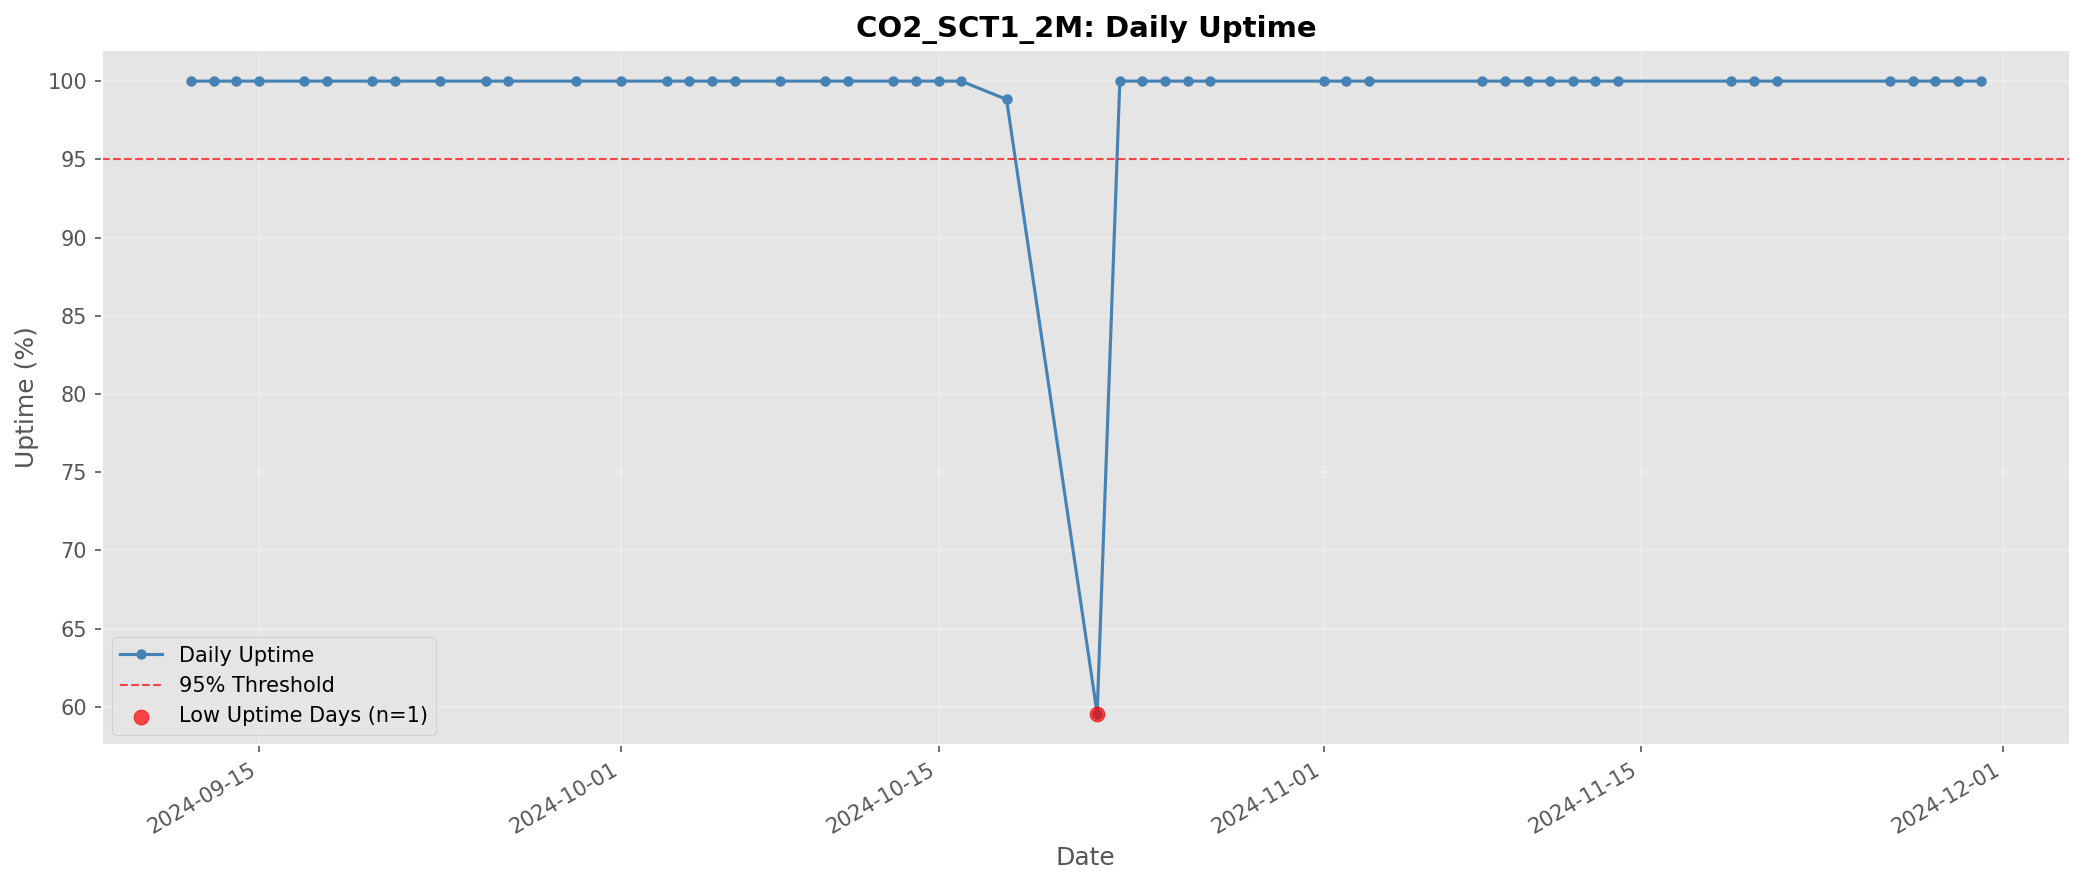

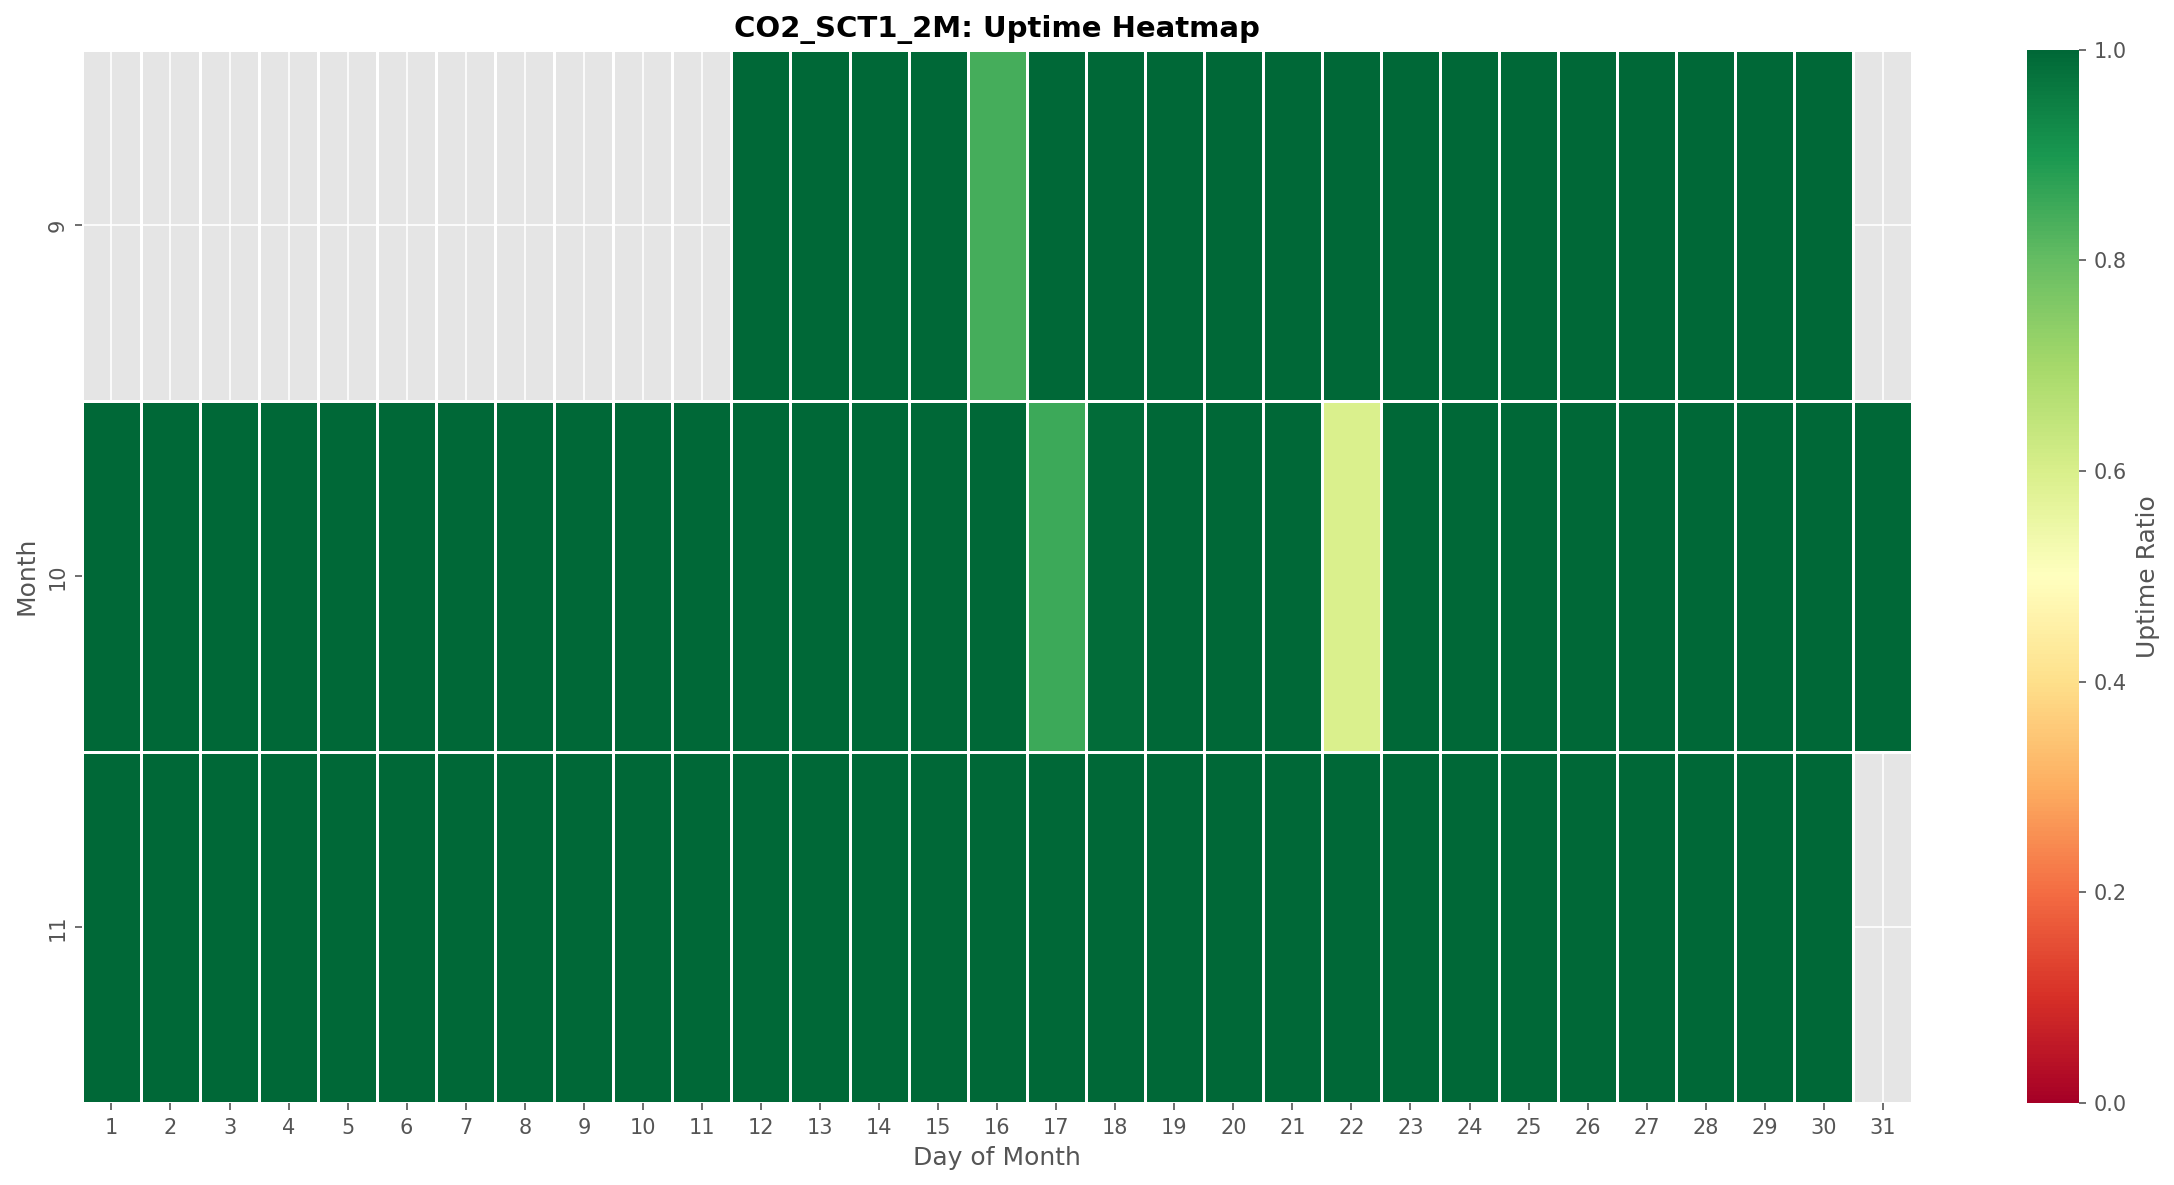

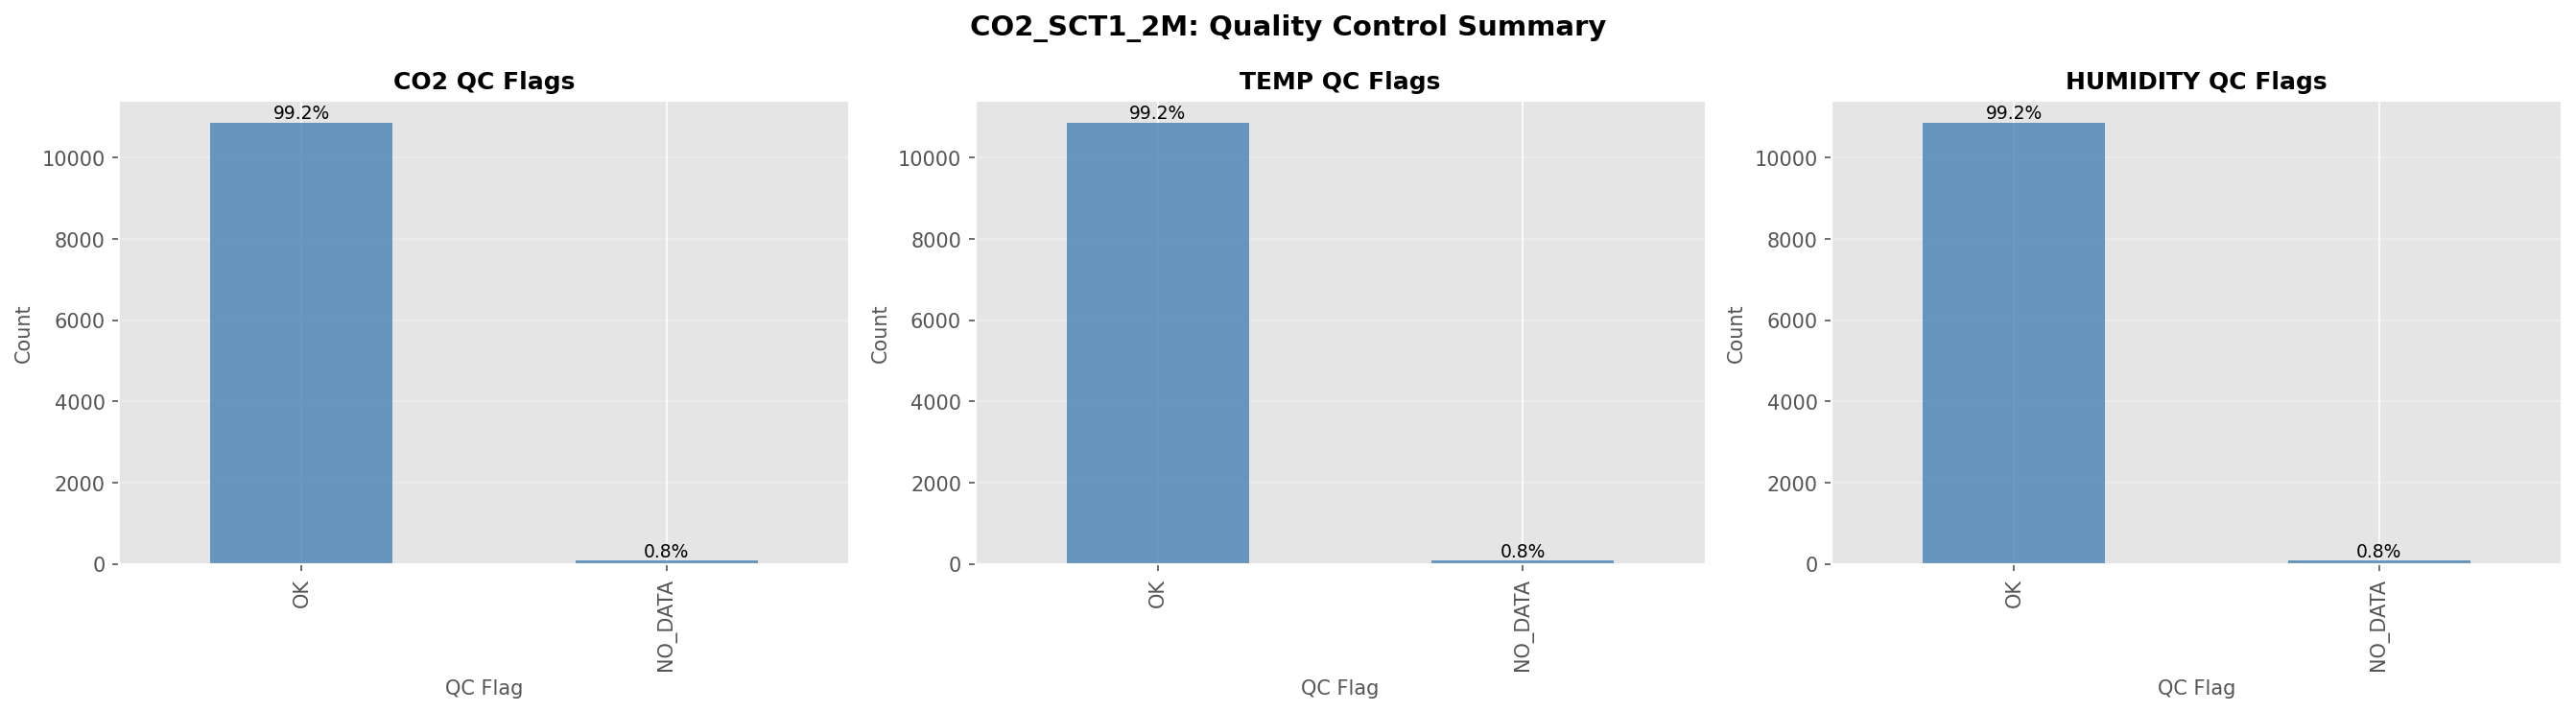

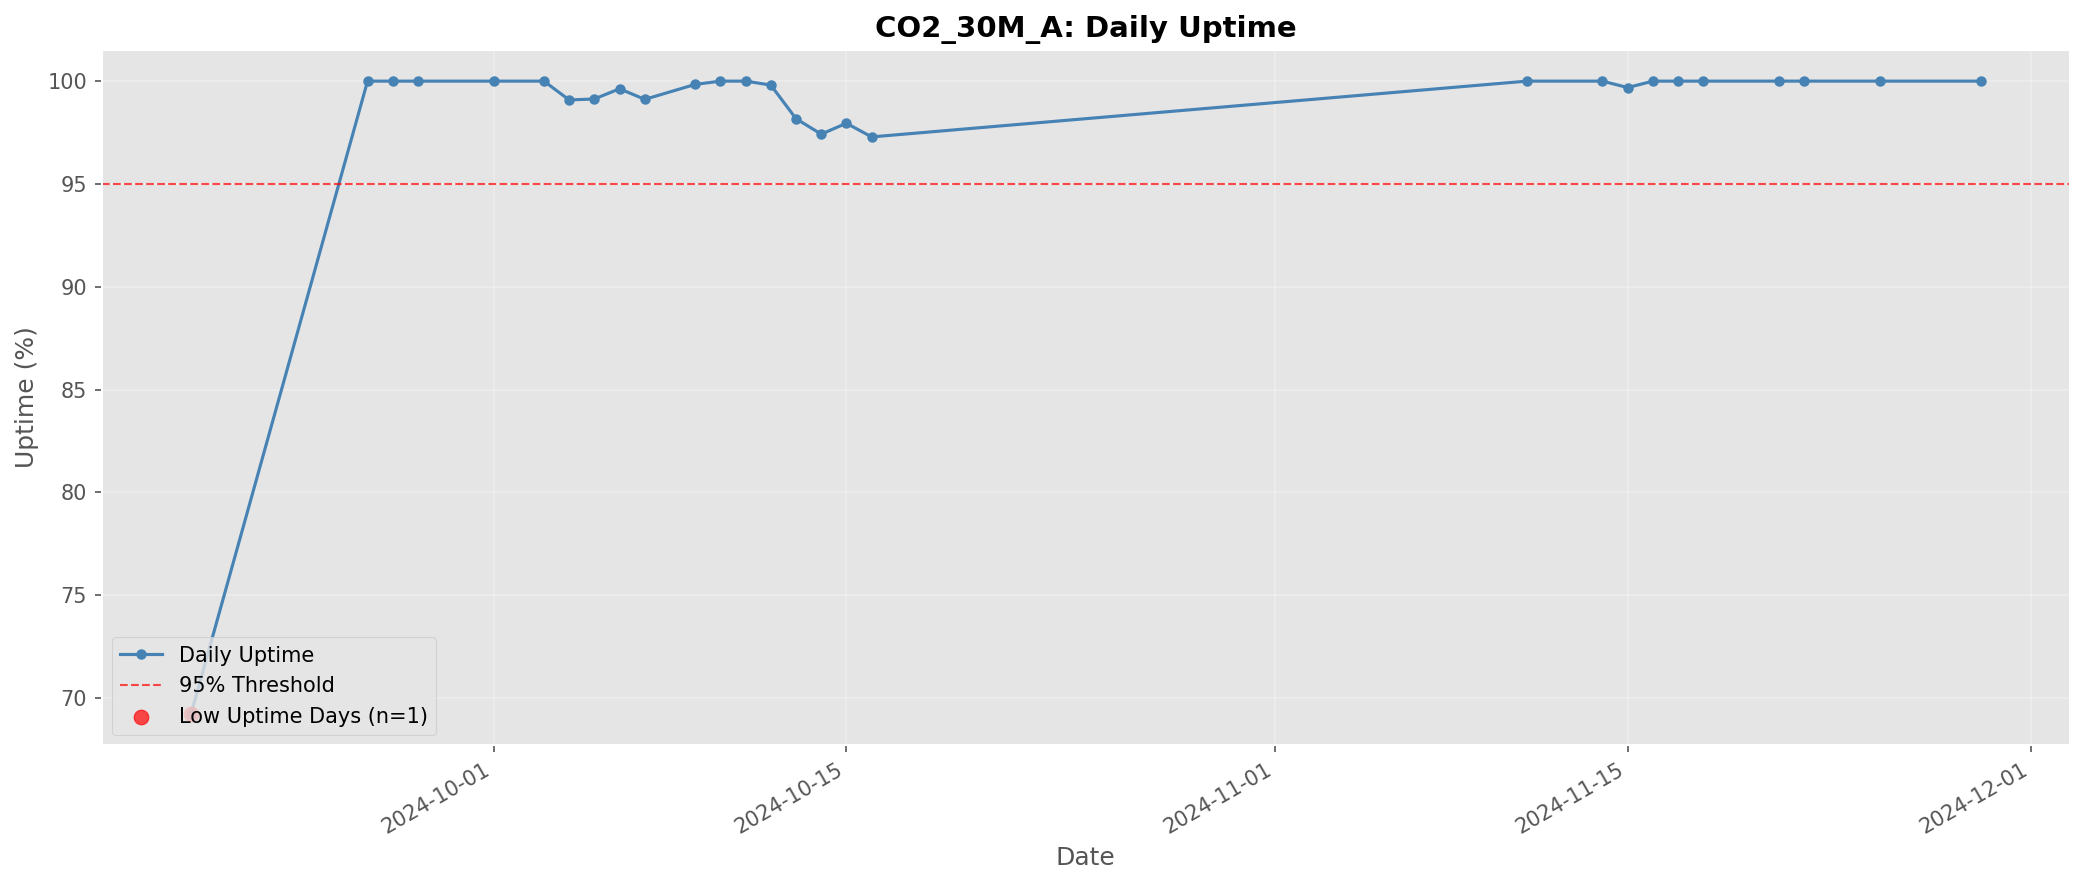

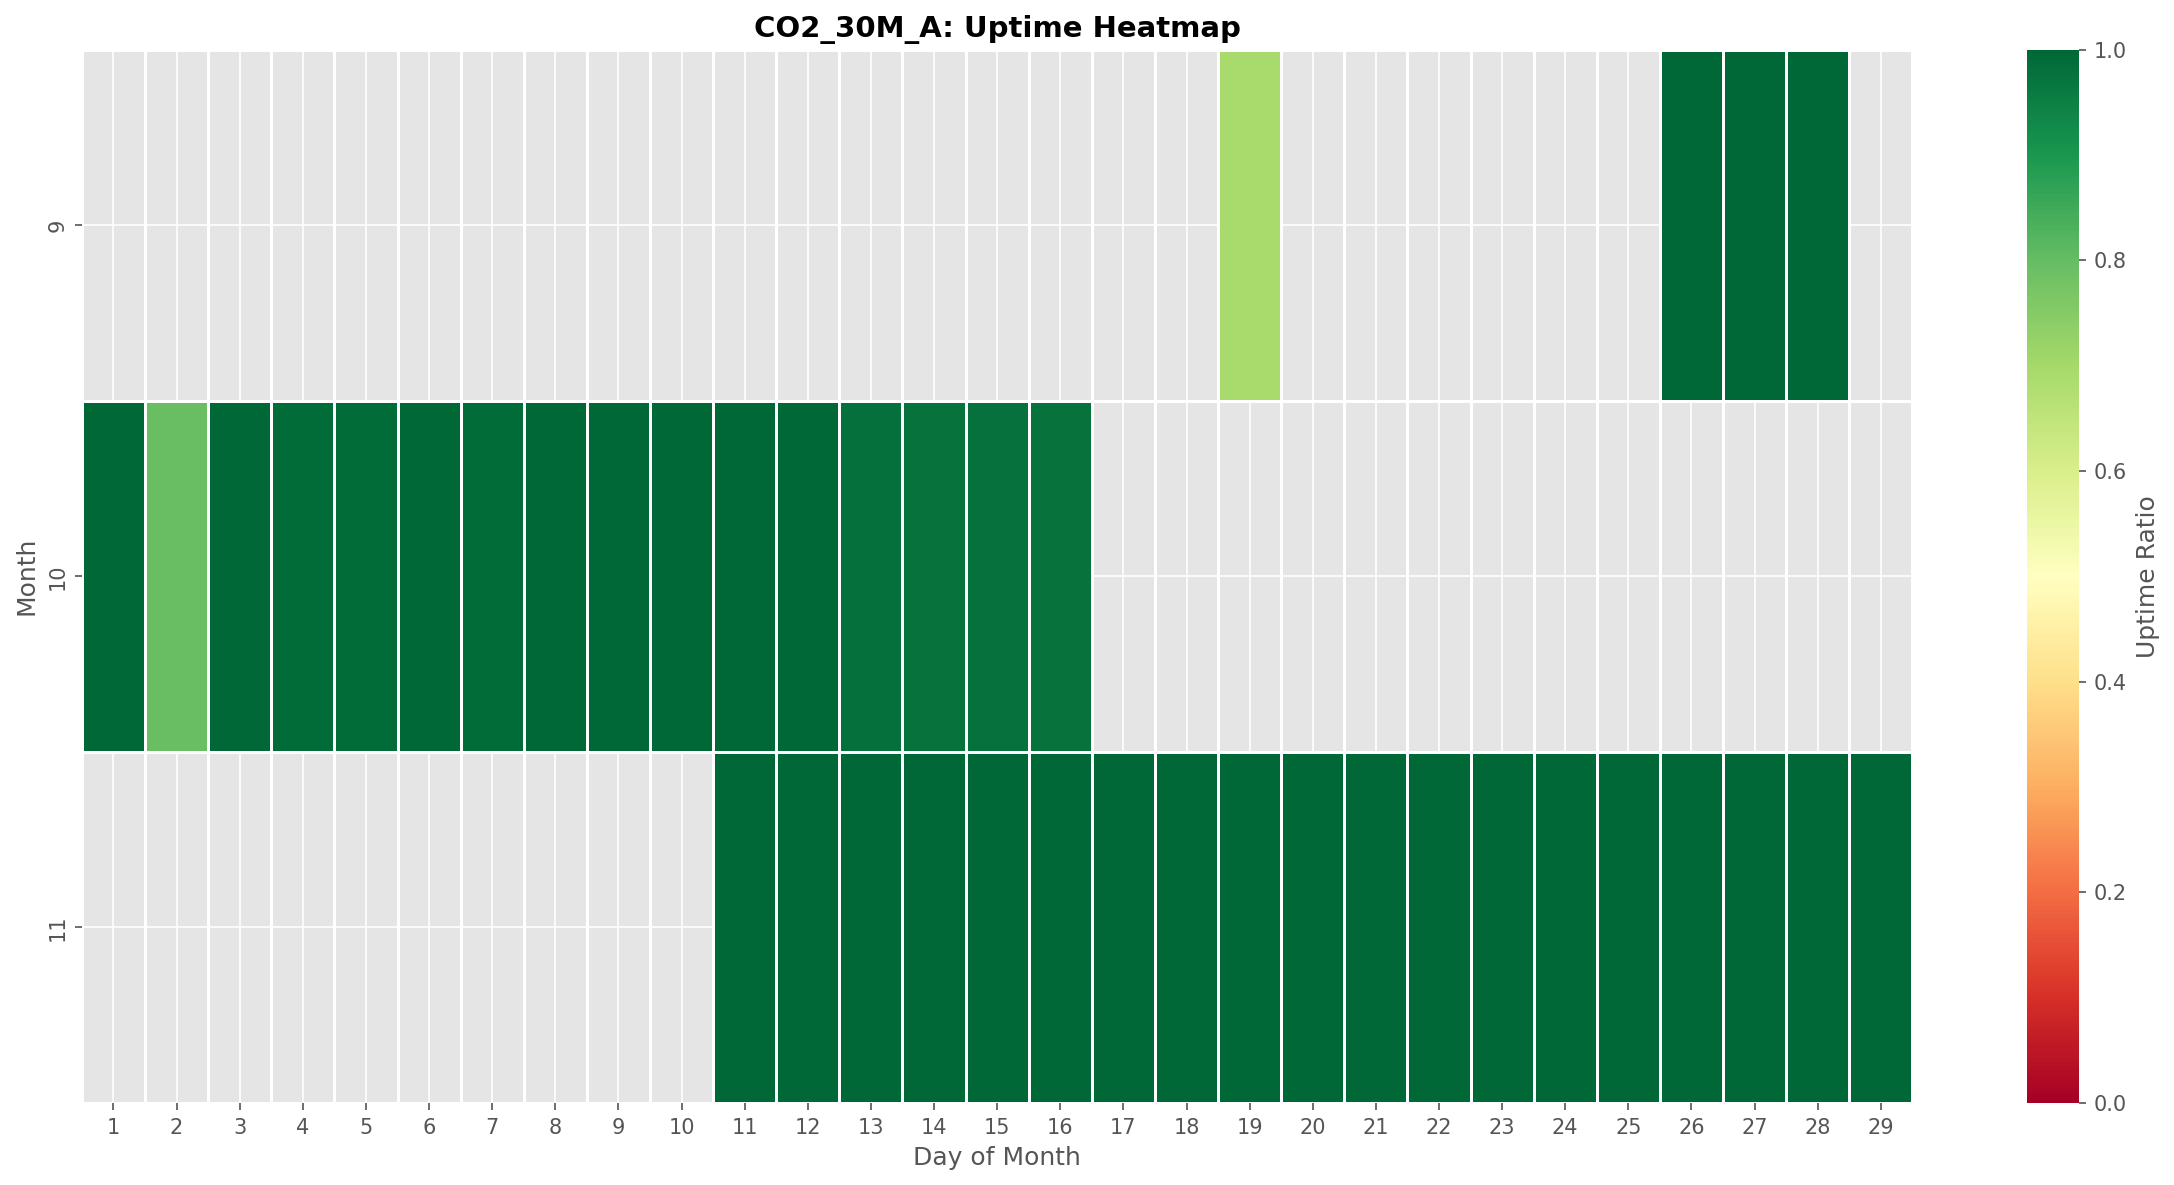

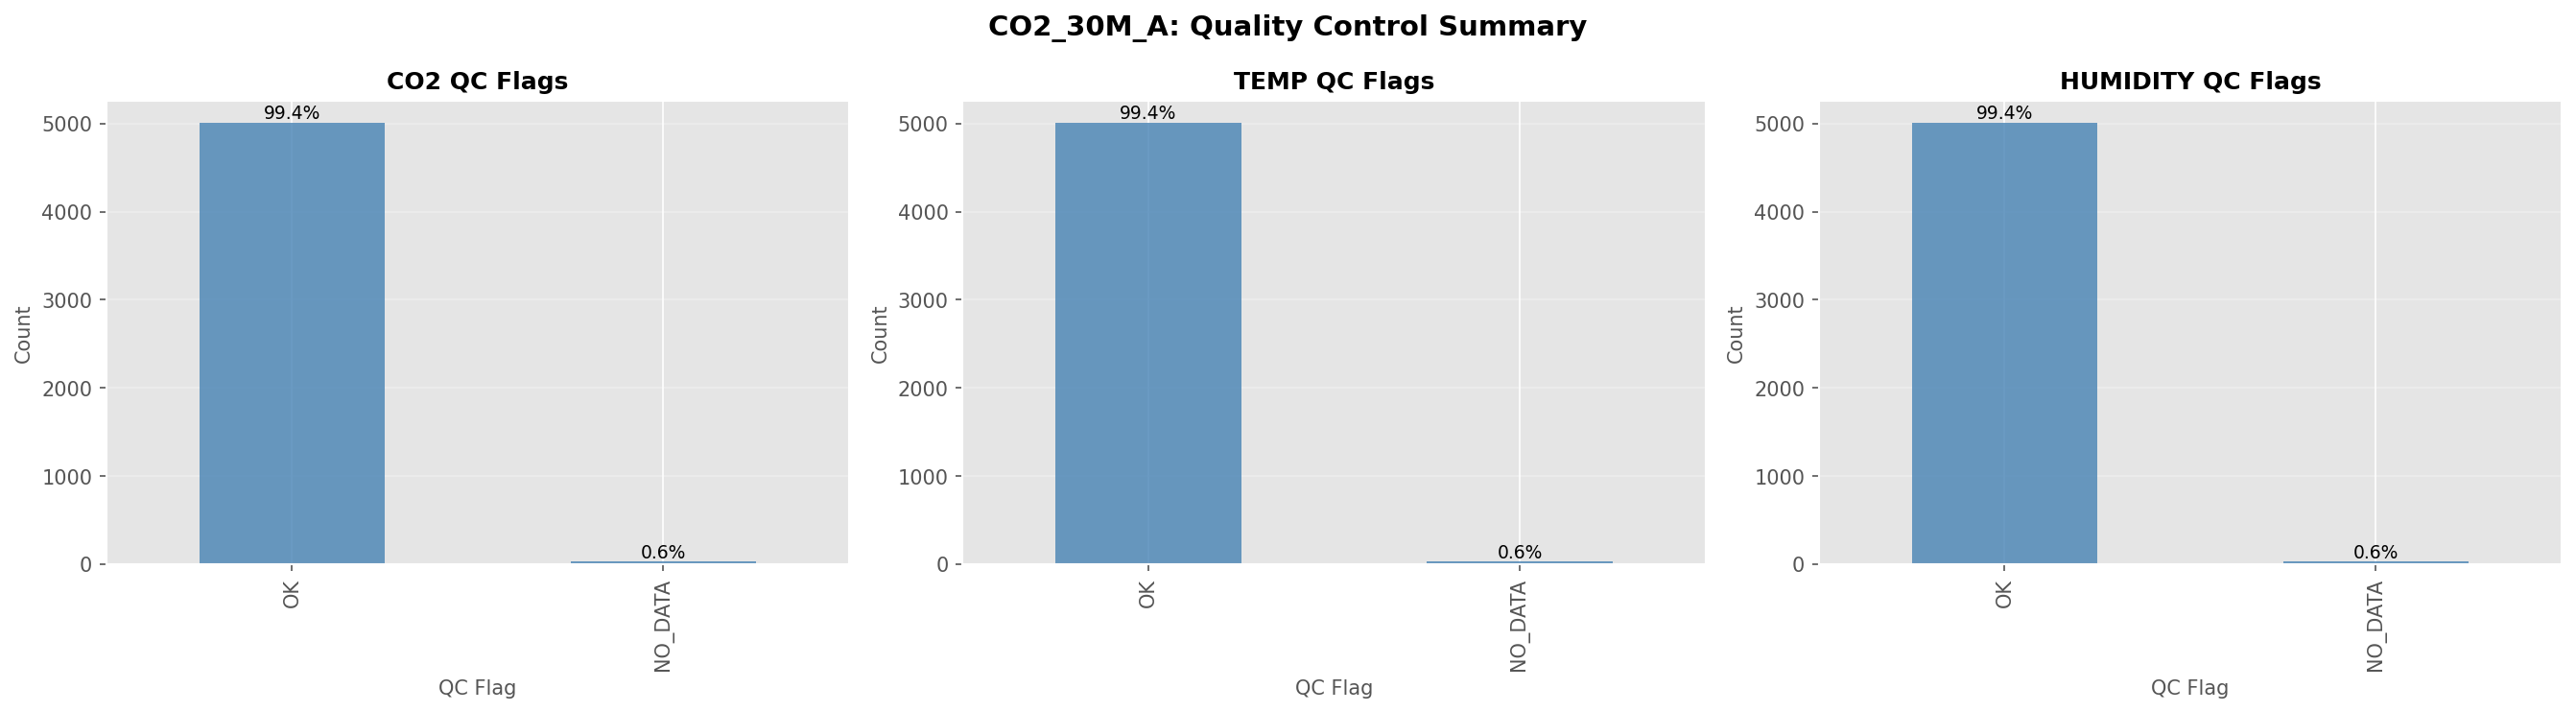

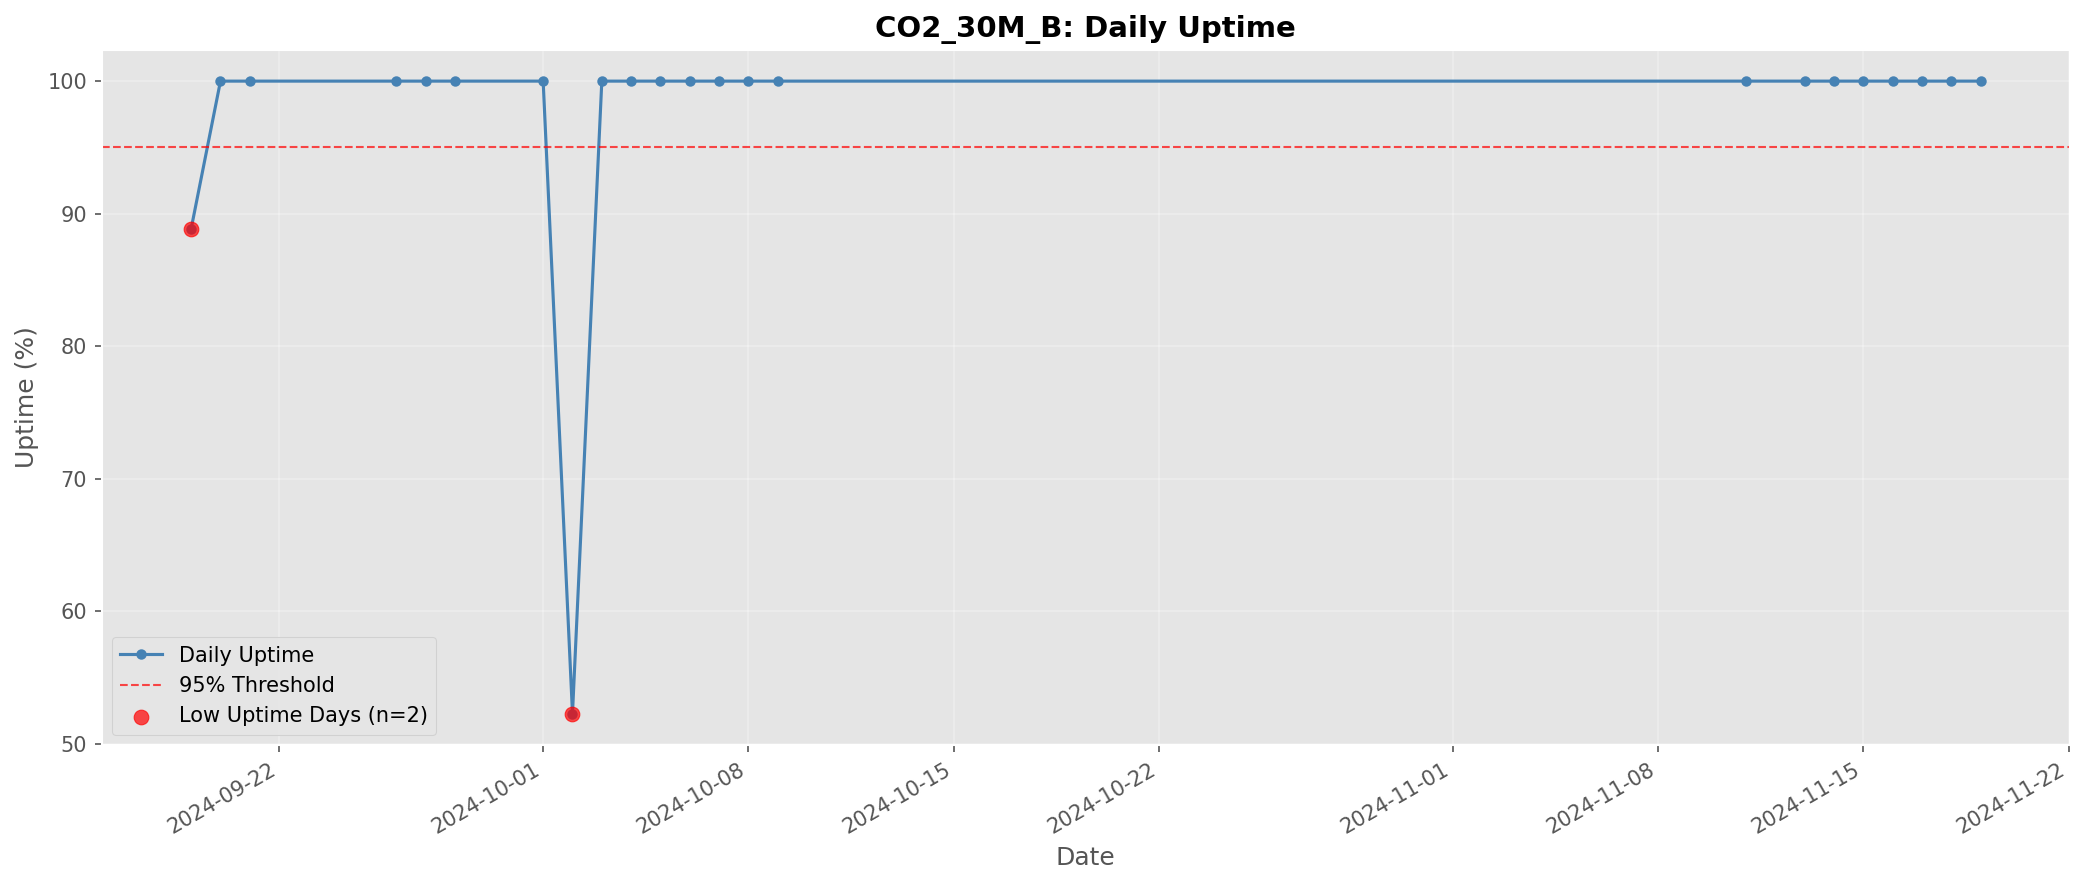

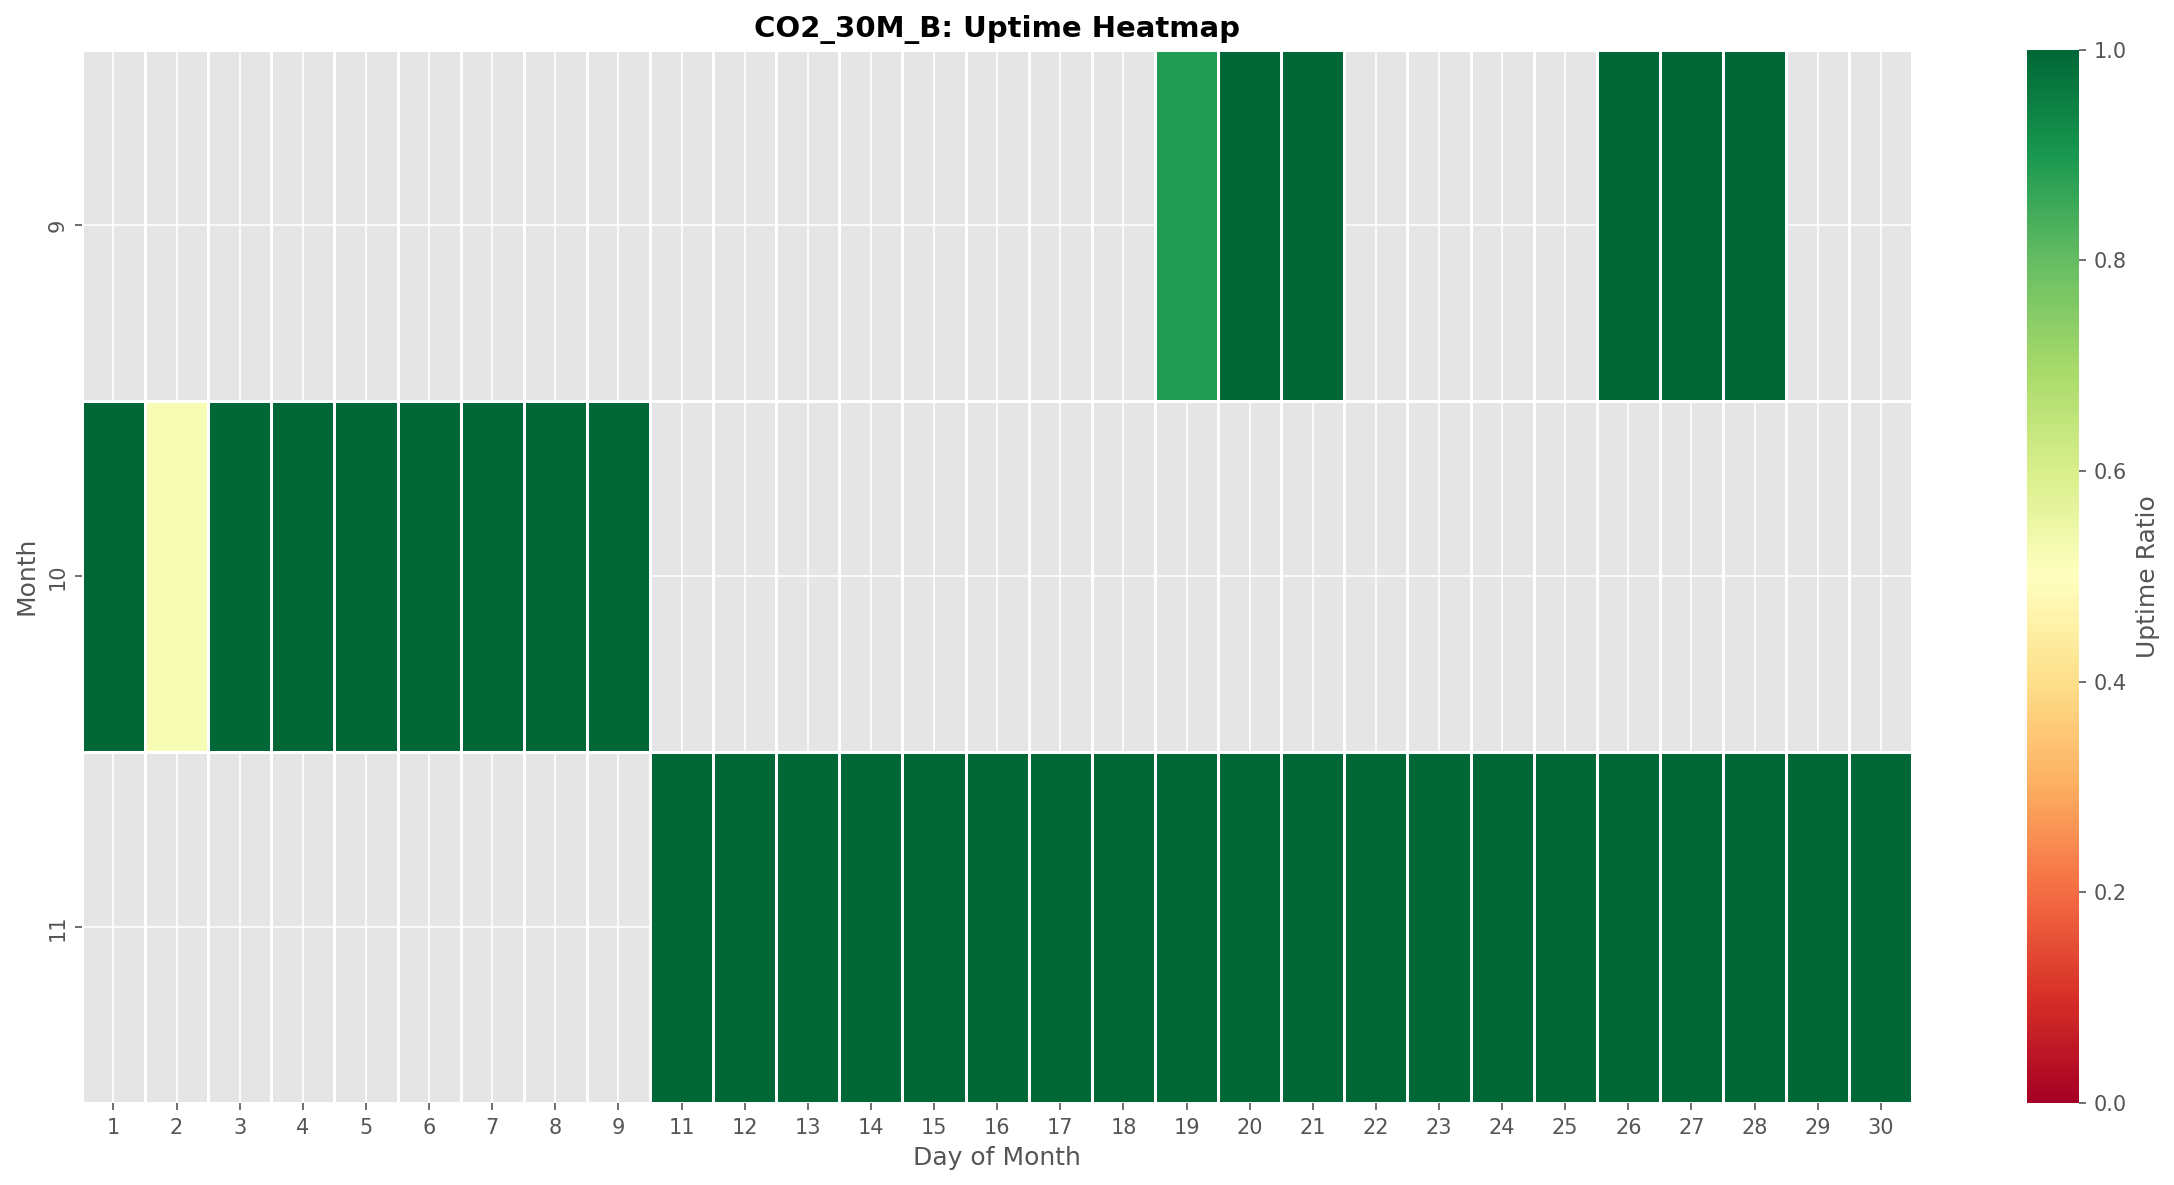

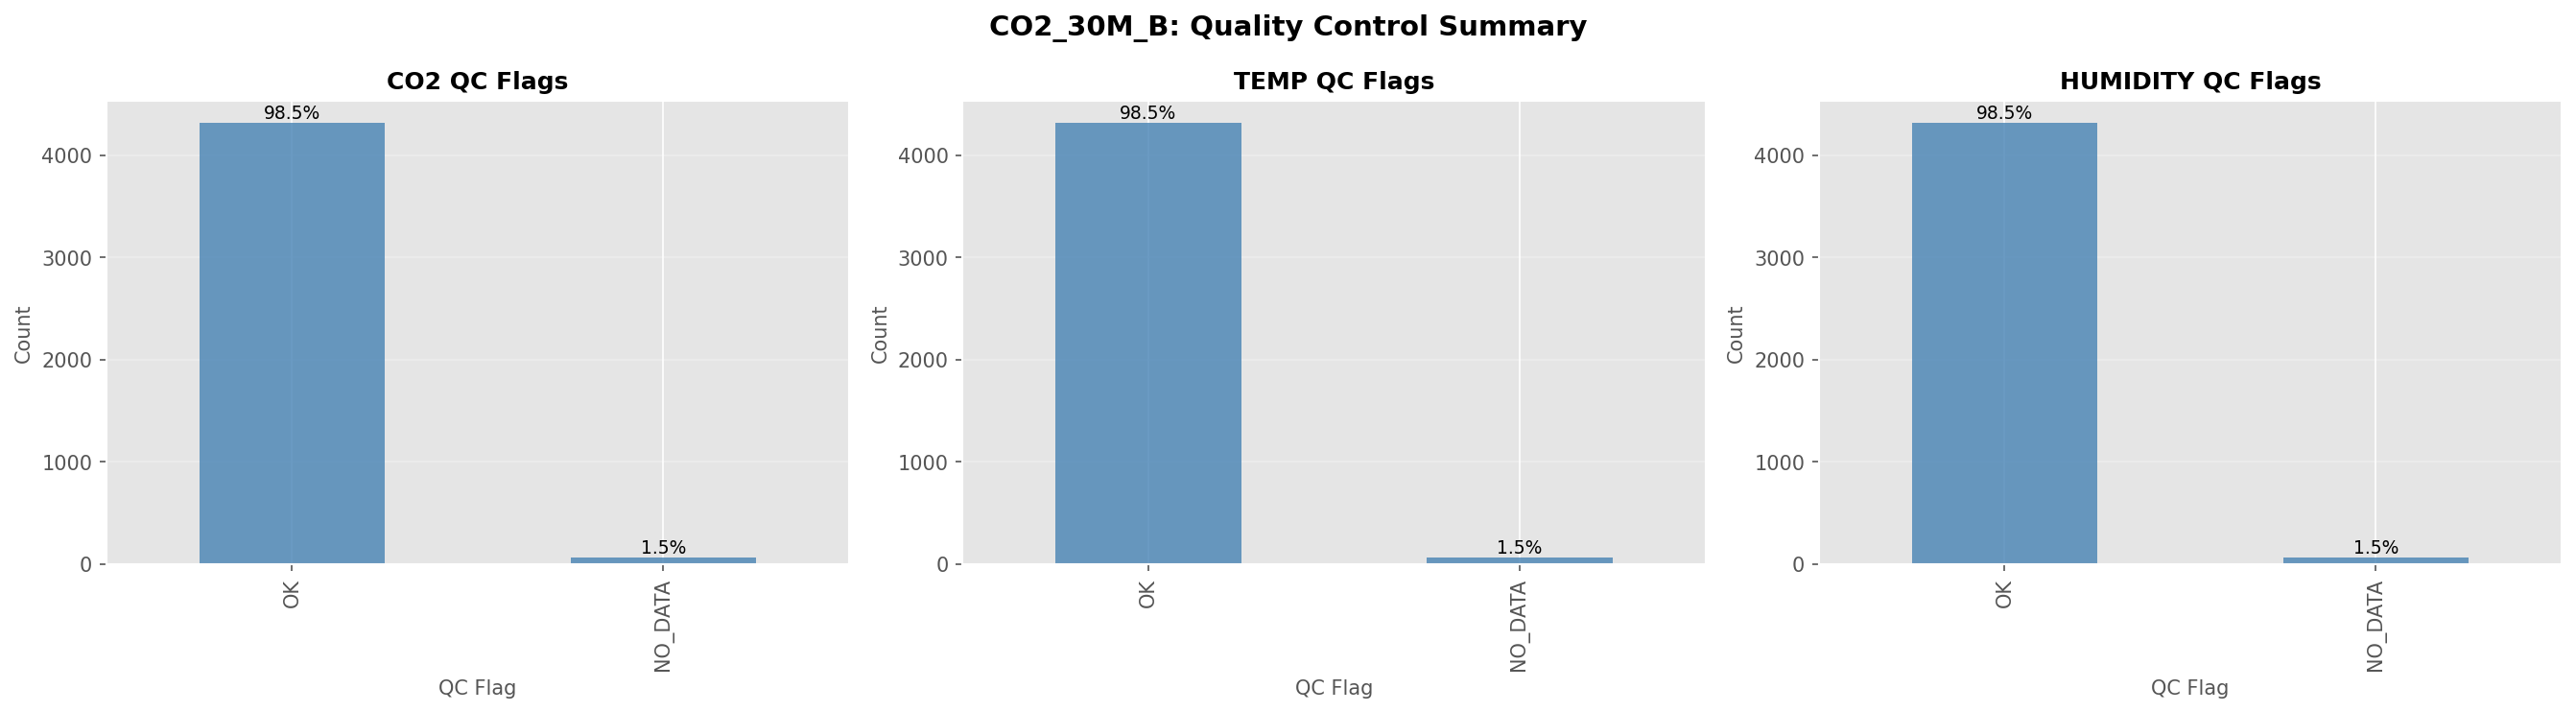

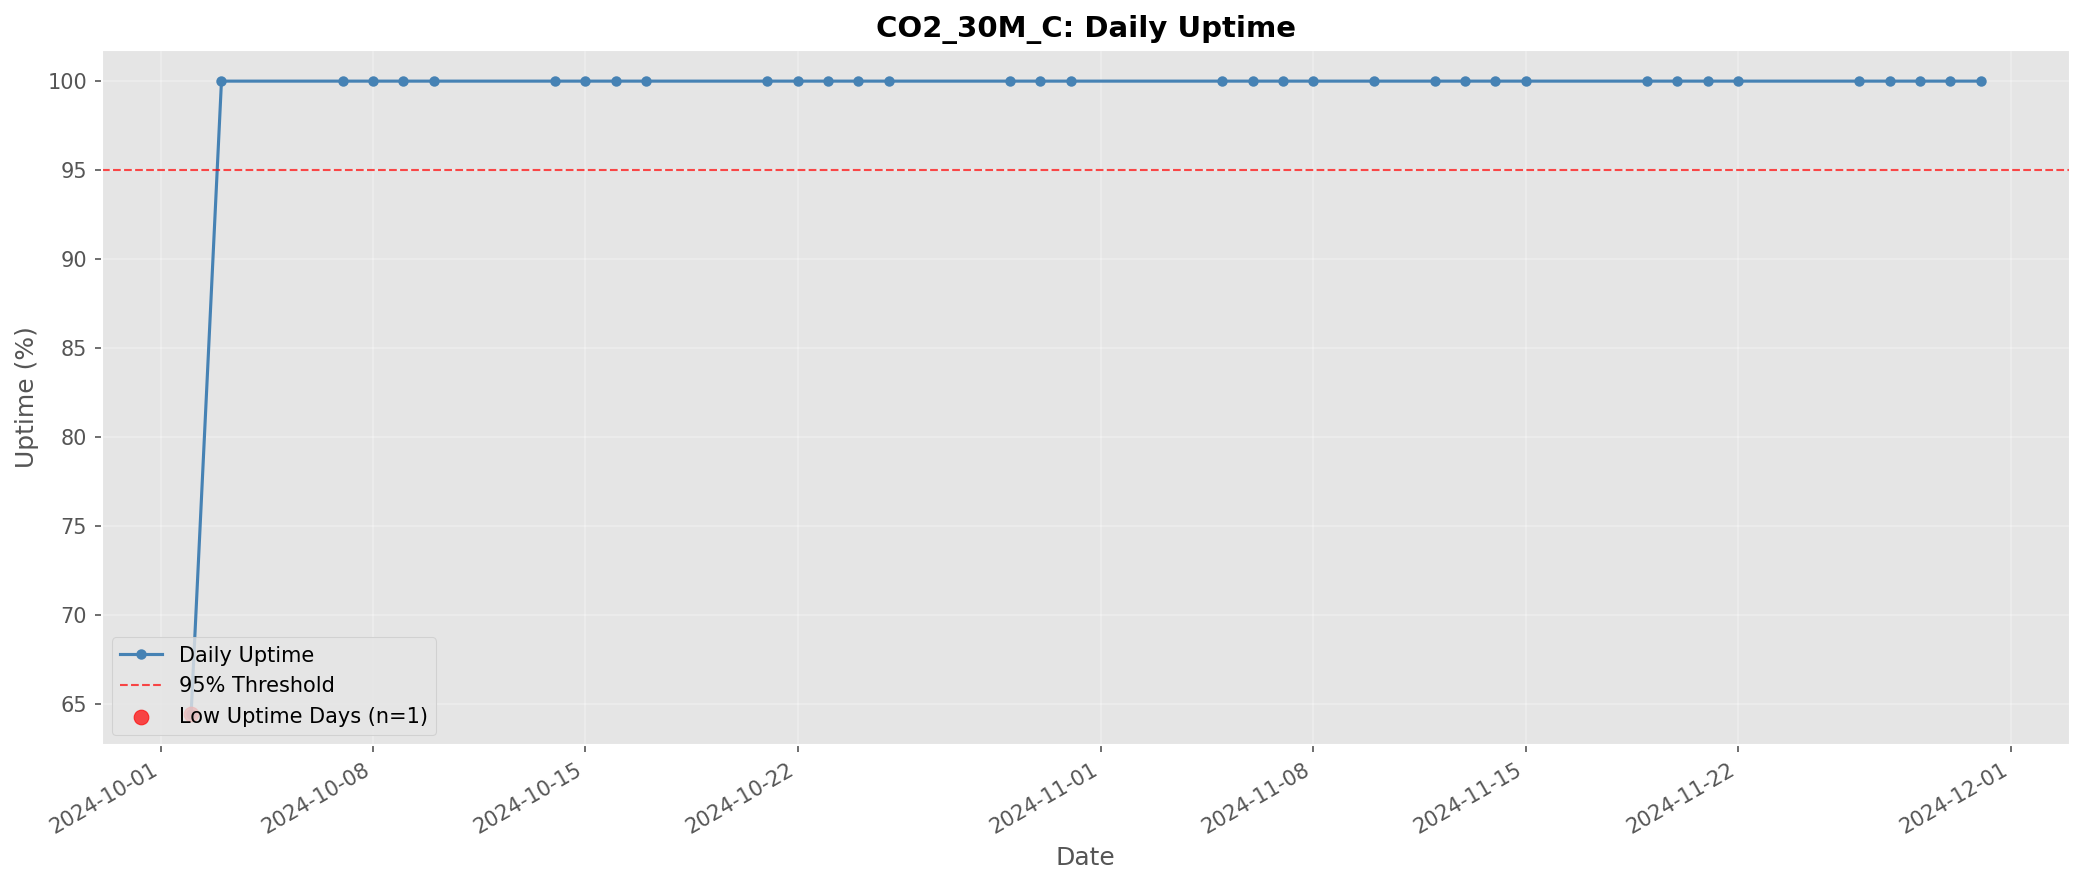

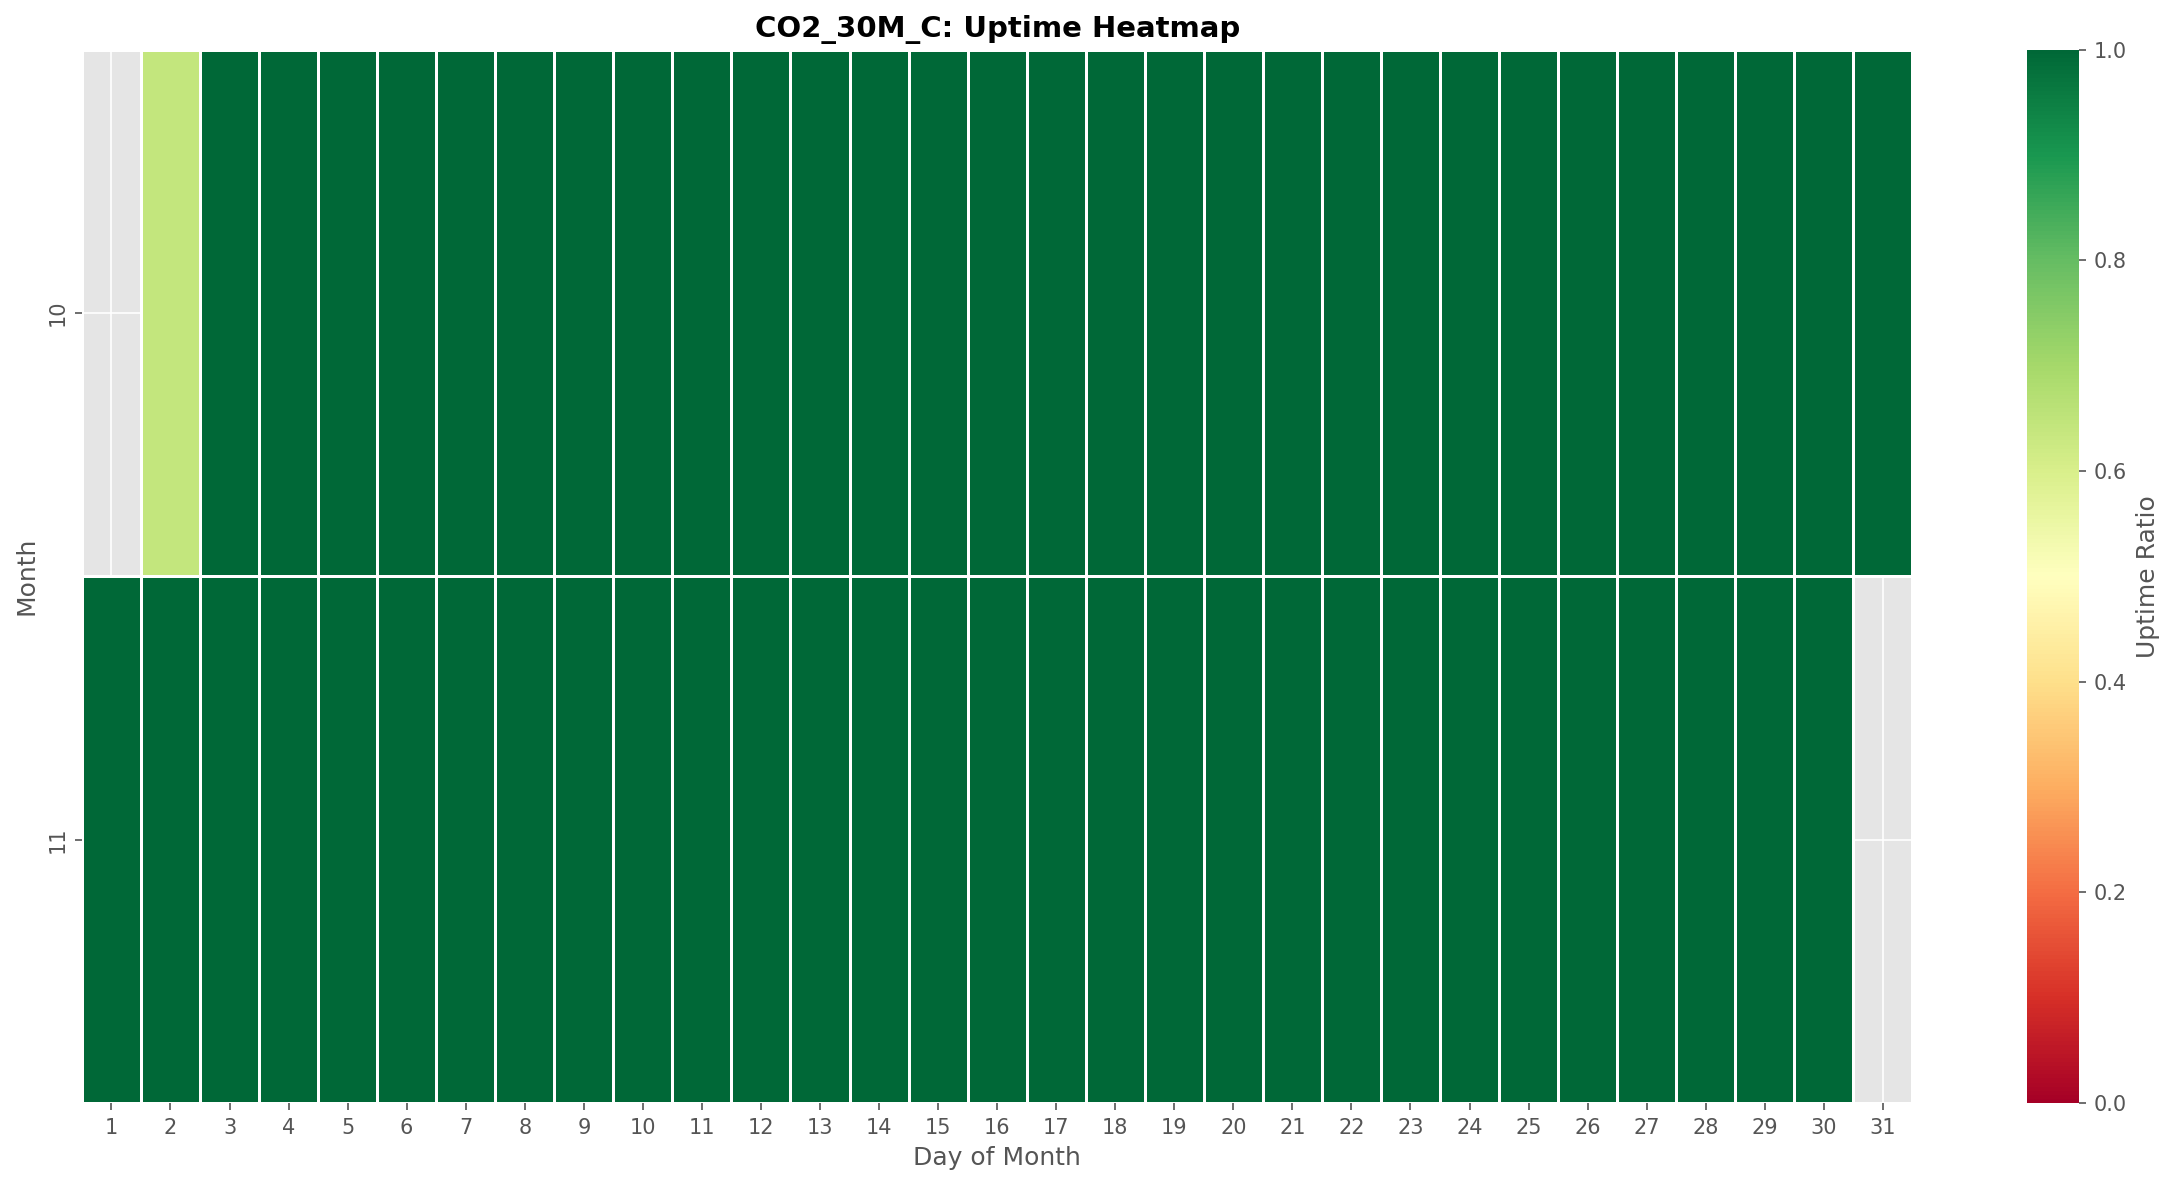

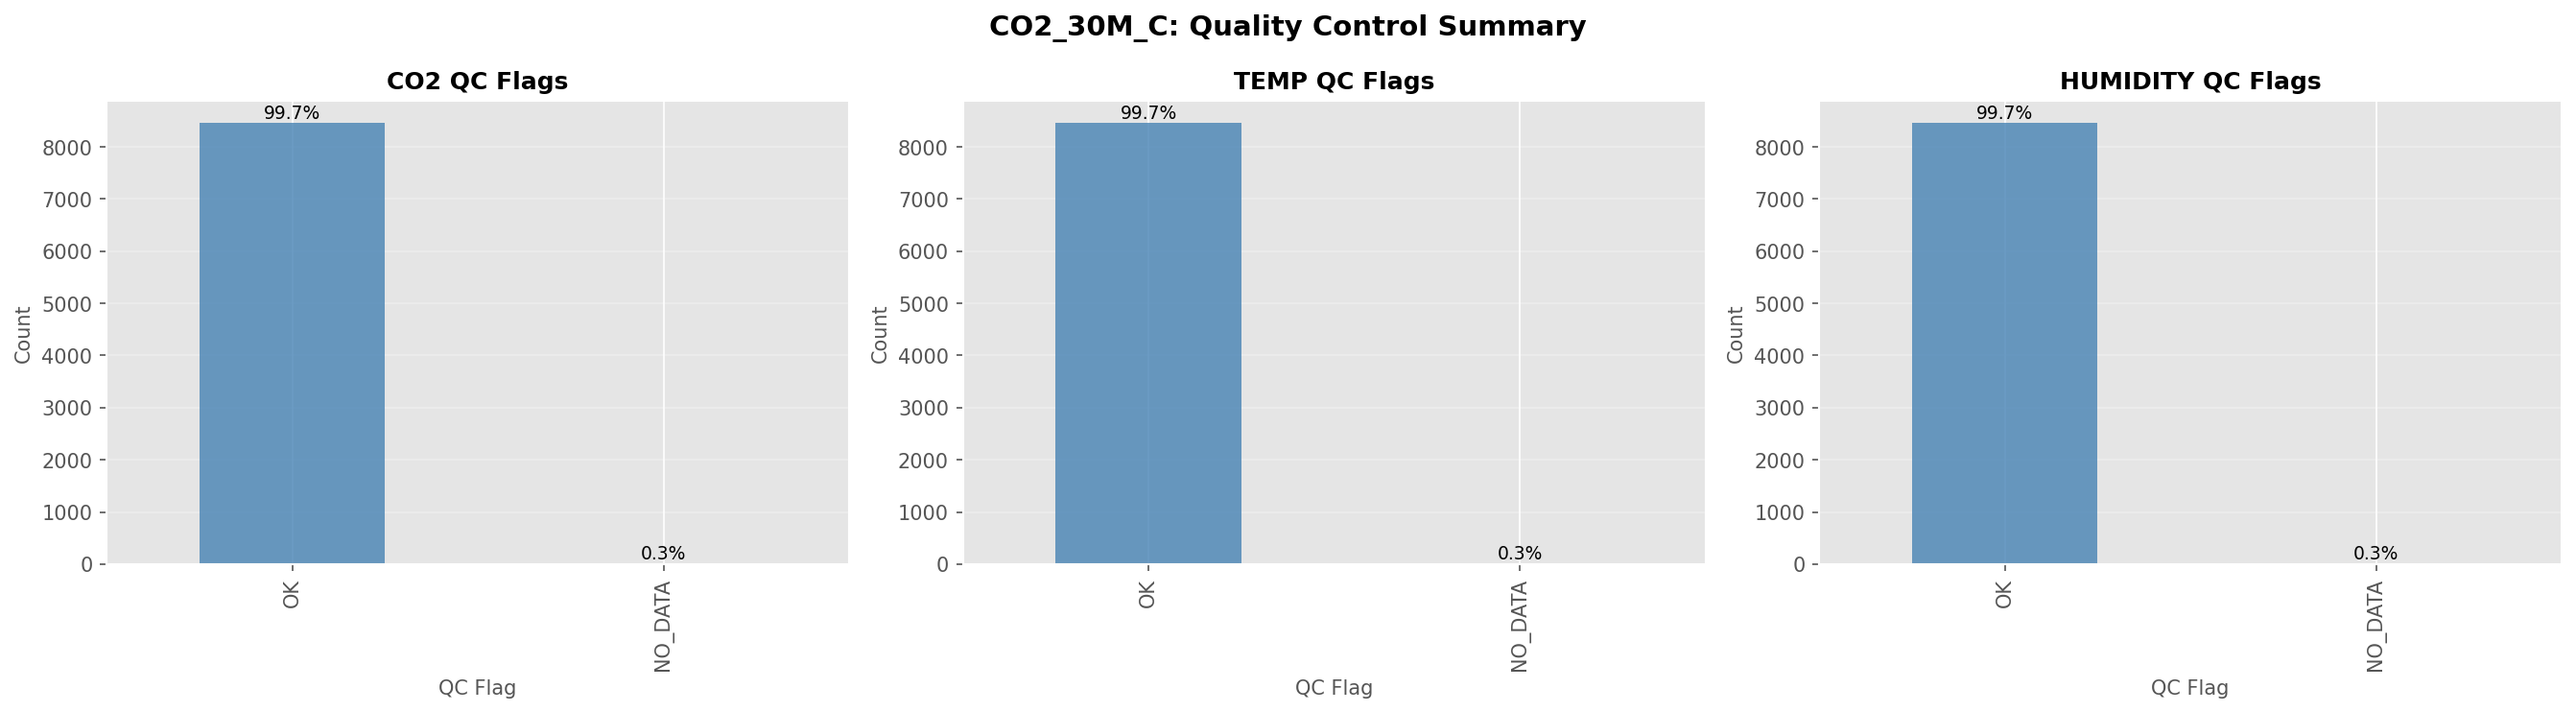

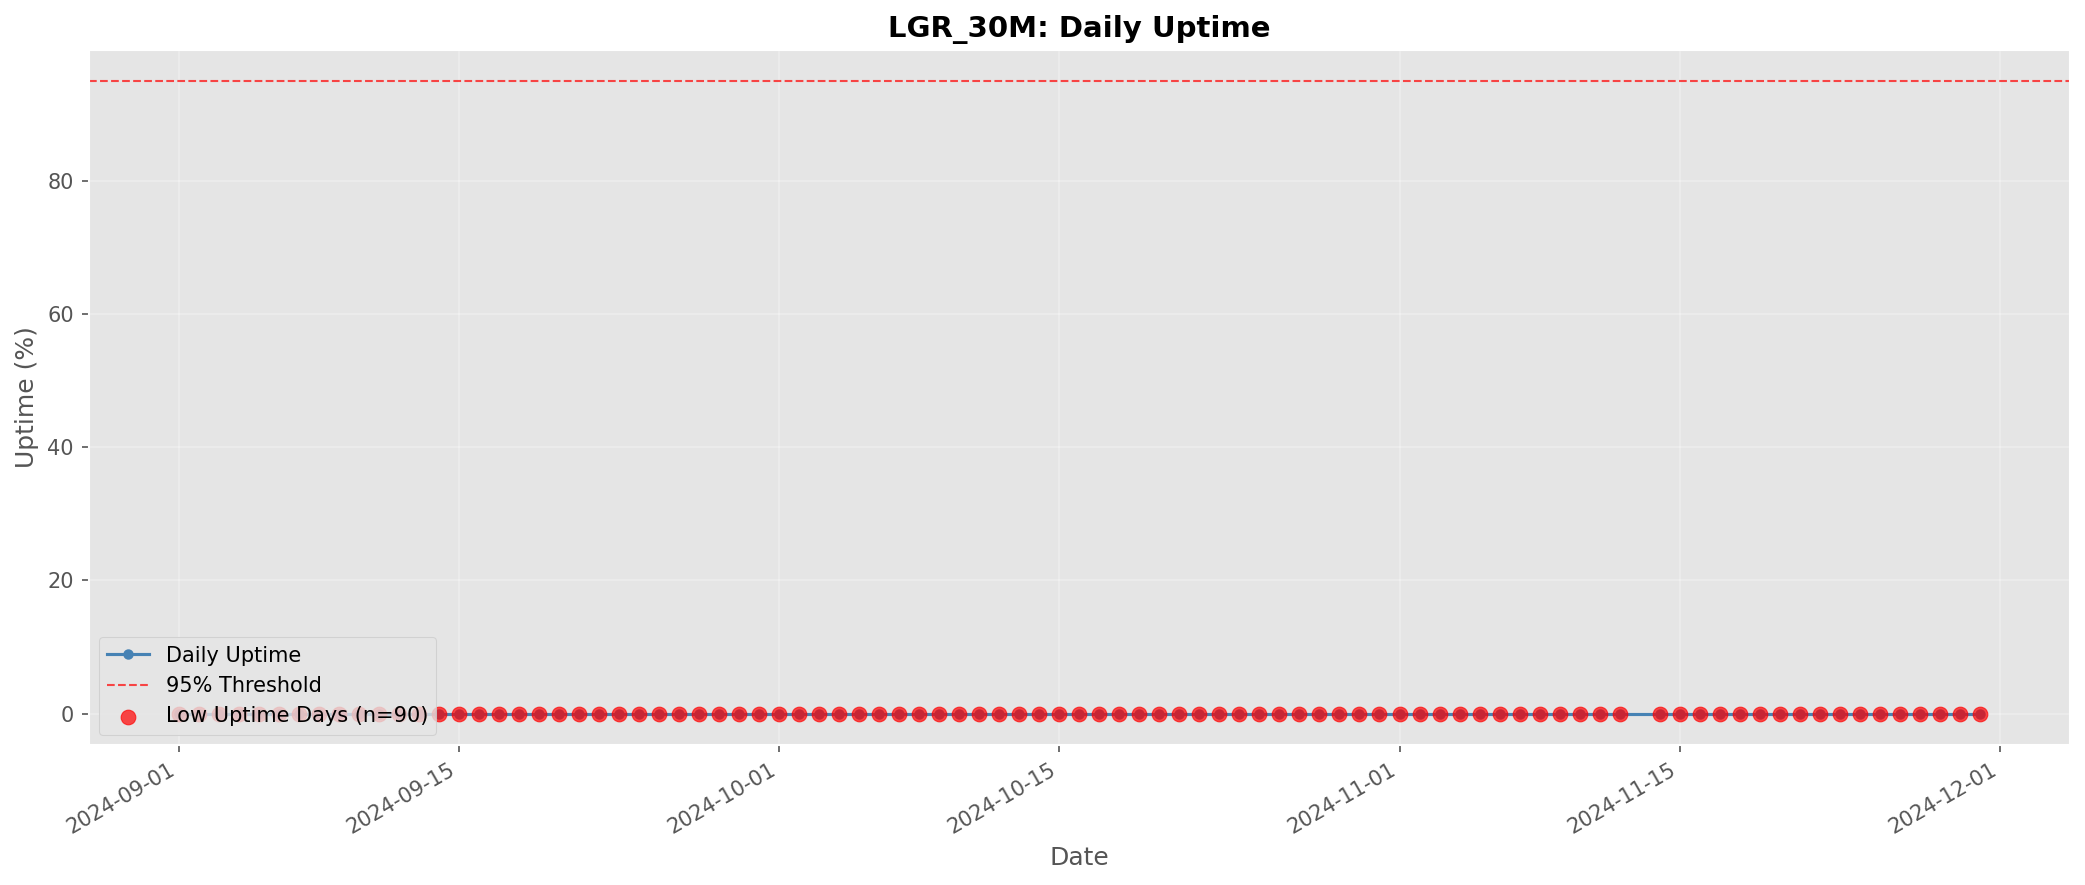

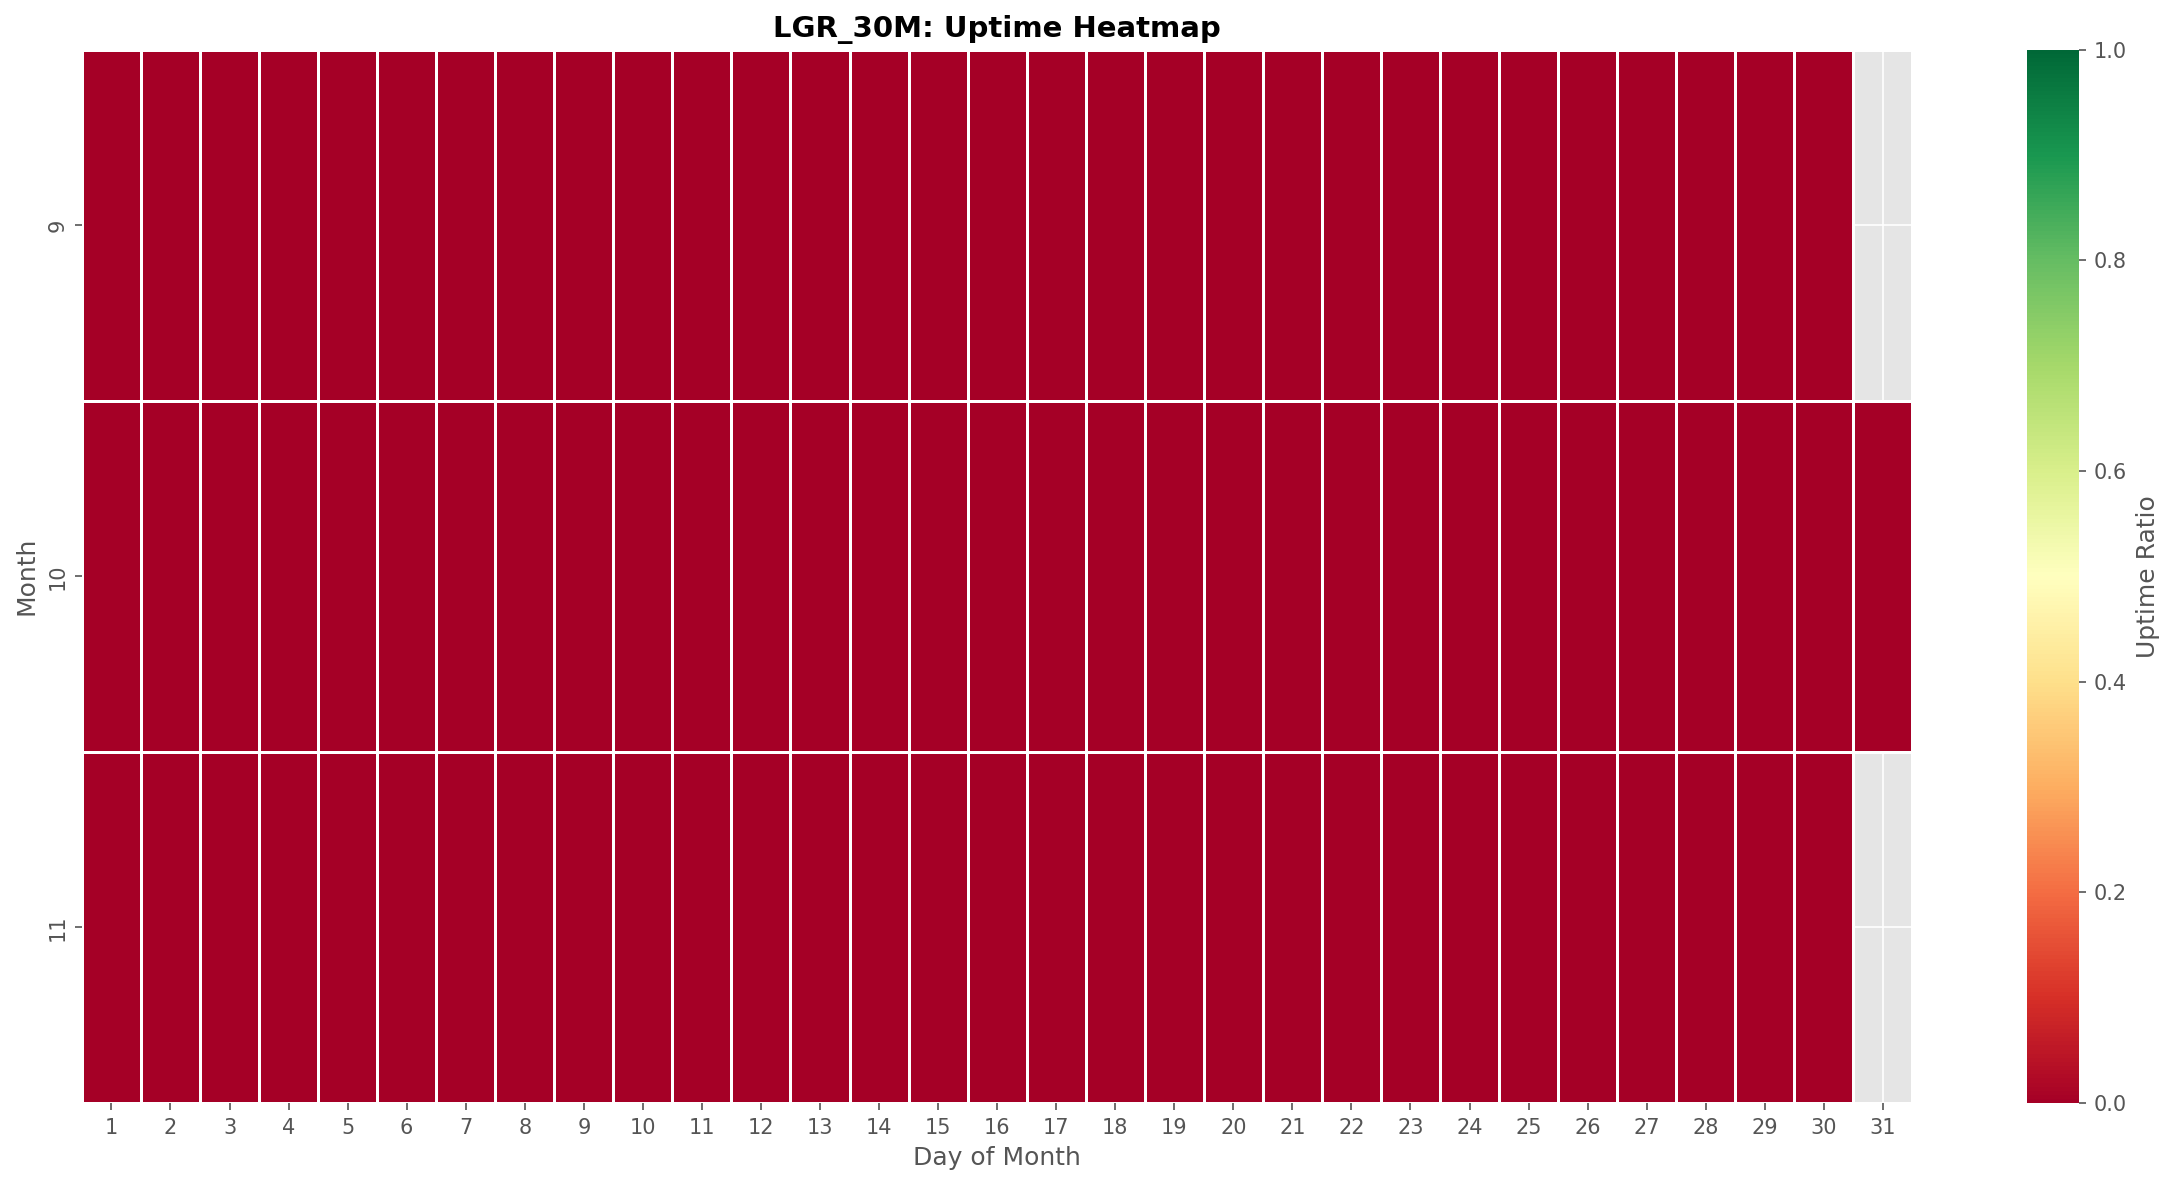

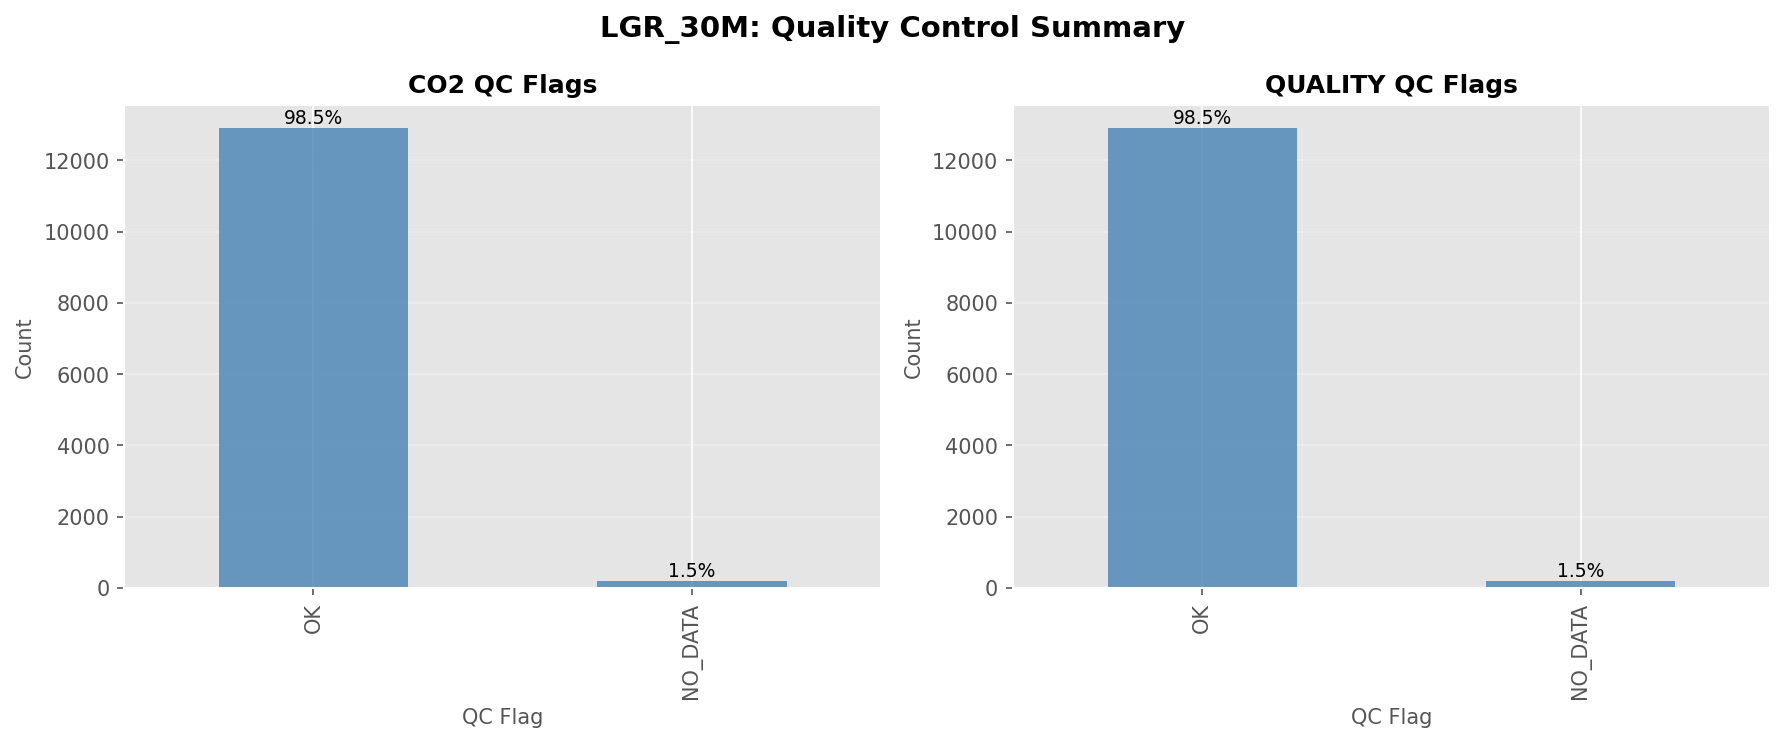

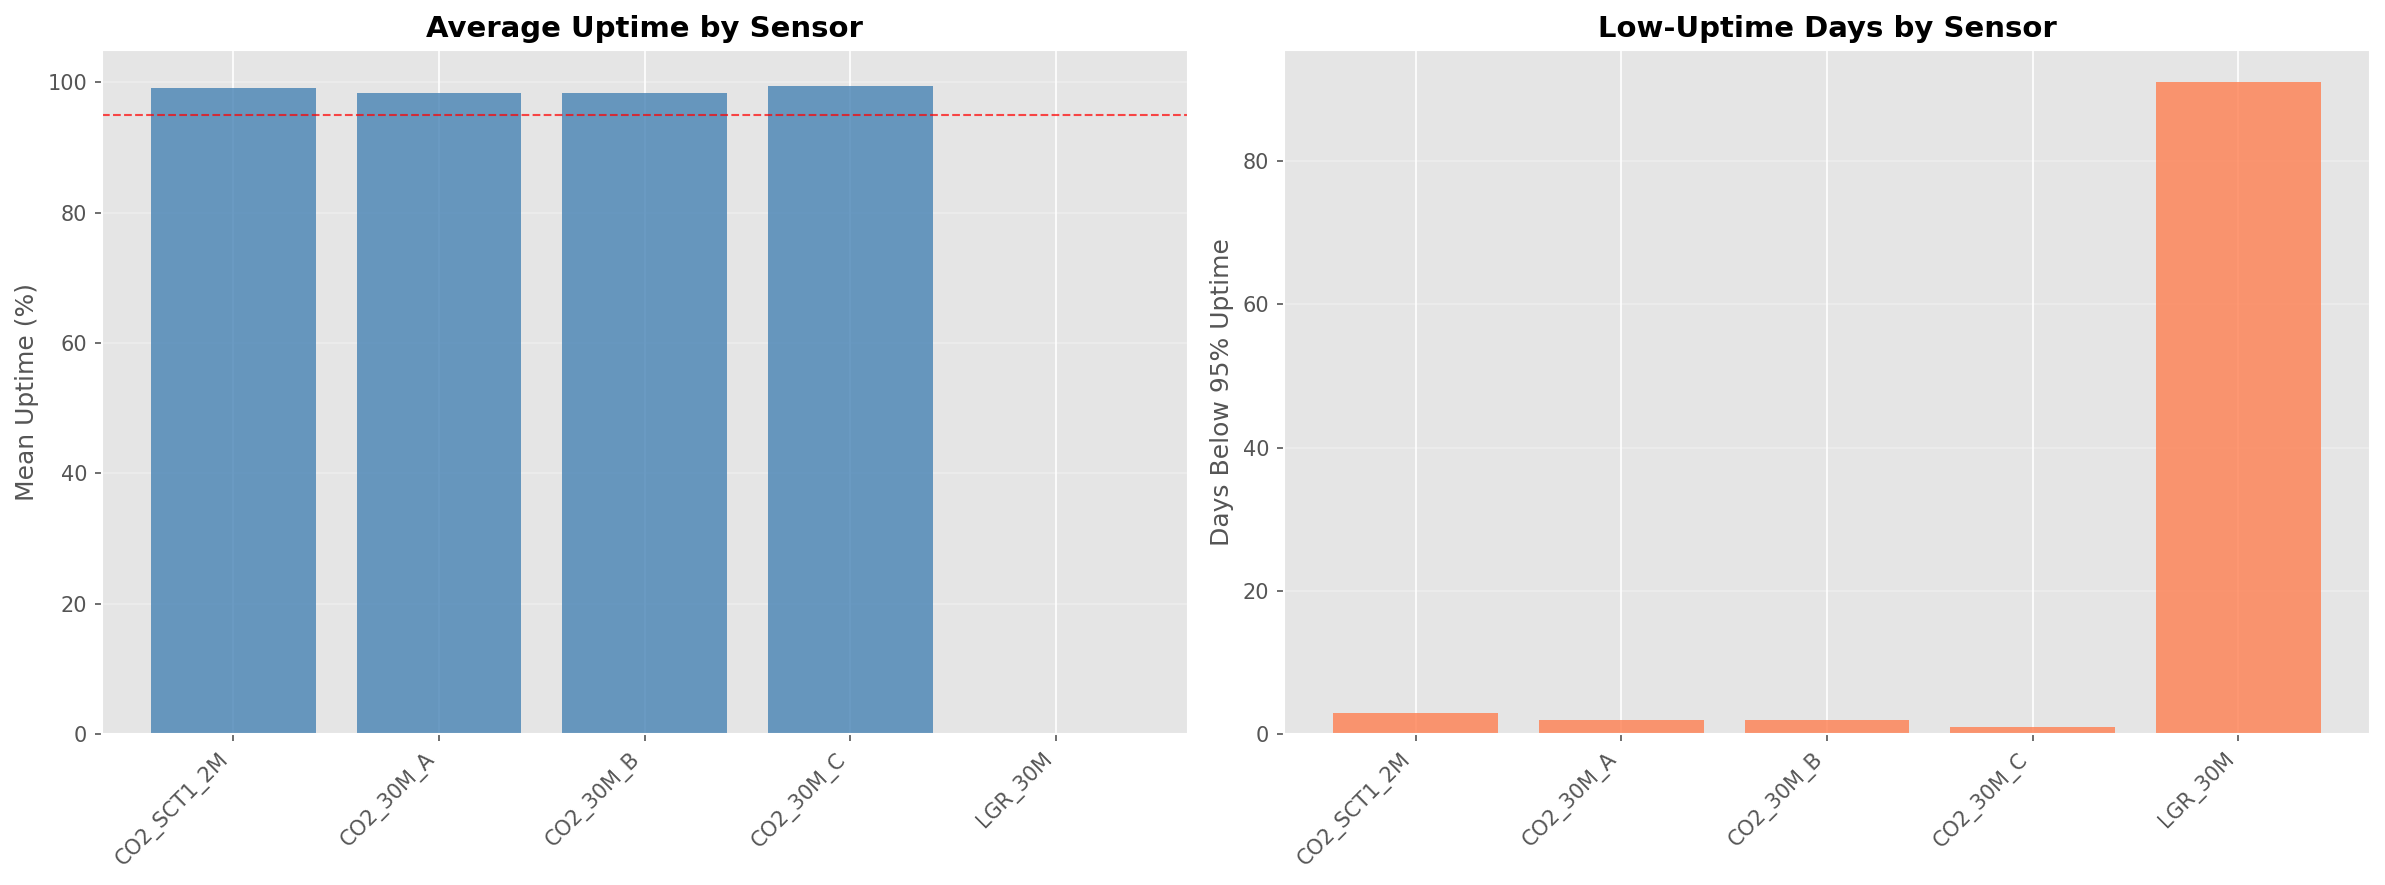

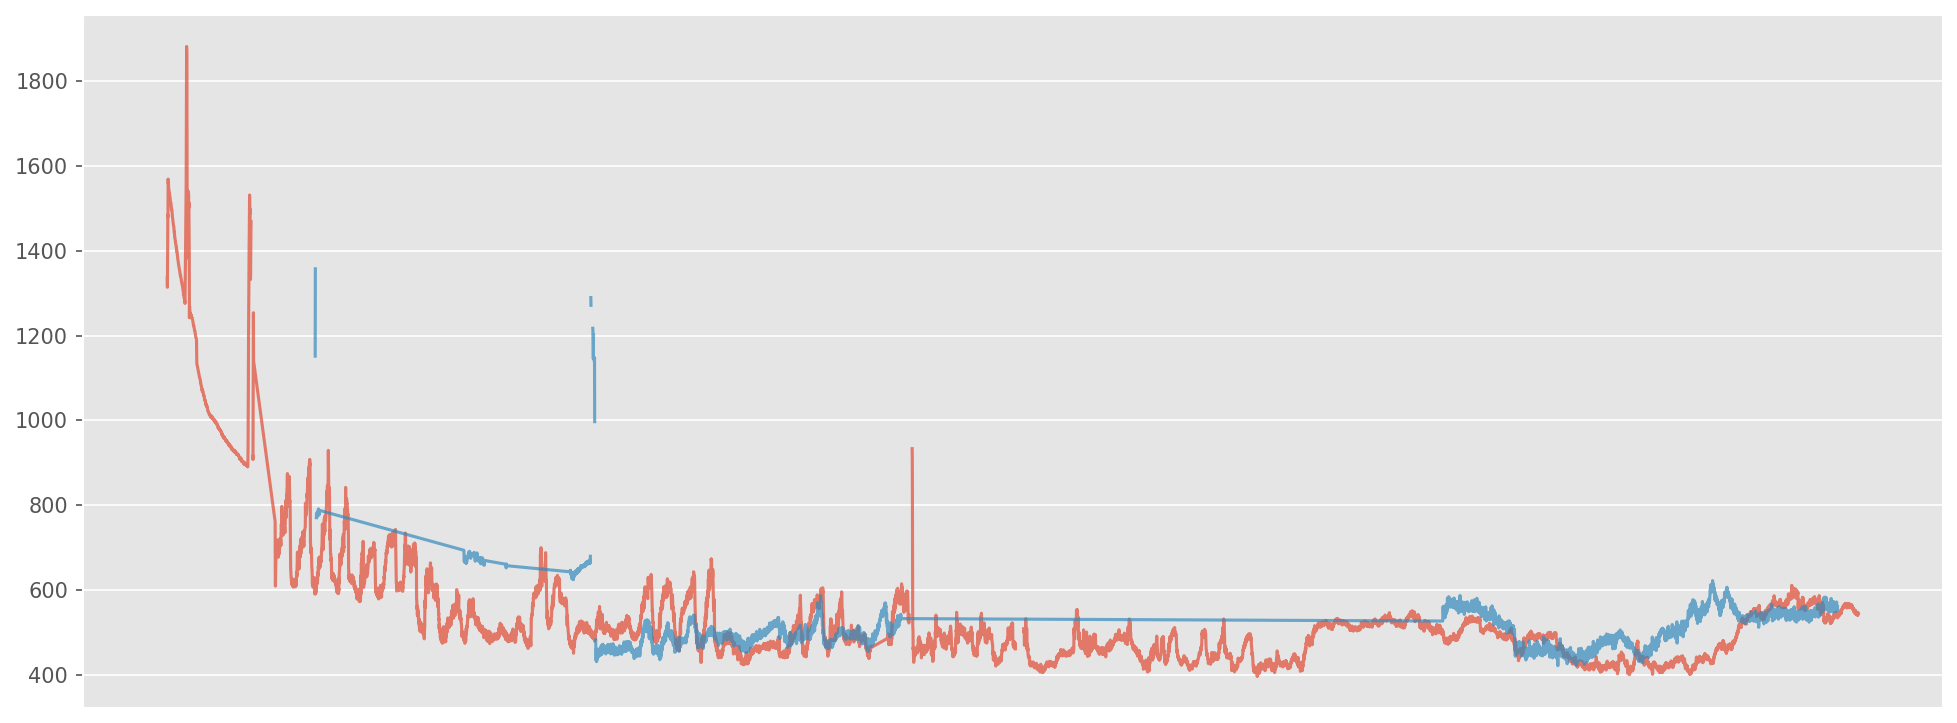

In [26]:
from src.visualization import generate_all_plots
generate_all_plots(config)

In [ ]:
# from src.taylor_diagram_custom import TaylorPlotter

# plotter = TaylorPlotter(output_dir=Path("output/plots"))

# # Simple: all sensors
# fig = plotter.plot_from_config(
#     config,
#     title="Taylor Diagram: SCD41 Sensors vs LGR Reference",
#     filename="taylor_all_sensors.png"
# )

# # Selective: only 30m sensors
# fig = plotter.plot_from_config(
#     config,
#     test_sensor_ids=['CO2_30M_A', 'CO2_30M_B', 'CO2_30M_C'],
#     title="Taylor Diagram: 30m Height Sensors",
#     filename="taylor_30m_only.png"
# )

from src.visualization import TaylorDiagram

taylor = TaylorDiagram(config.output_dir / "plots")
taylor.plot_from_config(config, normalize=True)